# Детекция свободных и занятых парковочных мест
**CSCI1409 · Bonus Project · Сагат Алихан**

Один полный кадр → рамки парковочных мест → классы `free` / `busy` и уверенность.

Этот ноутбук содержит подготовку 1 600 кадров CNRPark+EXT, проверку разметки, baseline и три эксперимента YOLO11n, выбор по validation, финальную оценку на test, подсчёт мест и разбор ошибок. Архитектура предобученная; наша работа — подготовка данных, дообучение и эксперименты.

**Источники:** [CNRPark+EXT, ODbL 1.0](https://cnrpark.it/), [Ultralytics YOLO11](https://docs.ultralytics.com/models/yolo11/). Использована помощь Codex; код и выводы нужно понимать для индивидуальной защиты.

## 1. Среда и запуск
В Colab выберите Runtime → Change runtime type → GPU. Локально откройте ноутбук в папке проекта. Если исходные кадры и CSV уже лежат рядом, код заново подготовит выборку. В чистом Colab загрузится готовый архив той же размеченной выборки из релиза репозитория.

`RUN_TRAINING=True` обучает все четыре модели. Для быстрого просмотра сохранённой модели поставьте `False`: данные и предсказания выполнятся, обучение пропустится. Все графики выводятся через Matplotlib в ноутбуке.

In [1]:
%pip install -q ultralytics==8.4.218 numpy==2.2.6 pandas==2.3.3 scikit-learn==1.7.2 matplotlib==3.10.7 Pillow==12.0.0 PyYAML==6.0.3

ERROR: Cannot install numpy==2.2.6 and ultralytics==8.4.218 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from IPython.display import display, Markdown
import csv, json, random, shutil, time, gc, hashlib, urllib.request, zipfile, platform, fcntl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import torch, ultralytics, yaml
from sklearn.model_selection import GroupShuffleSplit
from ultralytics import YOLO

SEED, MAX_IMAGES = 1409, 1600
IMAGE_WIDTH, IMAGE_HEIGHT = 1000, 750
ORIGINAL_WIDTH, ORIGINAL_HEIGHT = 2592, 1944
EPOCHS, BATCH_SIZE = 10, 8
RUN_TRAINING = True
PROJECT = Path.cwd()
# Hold one process lock for the full notebook run: do not rebuild data during training.
TRAINING_LOCK = (PROJECT / ".parking_training.lock").open("a+")
try:
    fcntl.flock(TRAINING_LOCK, fcntl.LOCK_EX | fcntl.LOCK_NB)
except BlockingIOError:
    raise RuntimeError("Another project run is active. Wait for it to finish before Run All.")
FRAMES = PROJECT / "CNR-EXT_FULL_IMAGE_1000x750" / "FULL_IMAGE_1000x750"
OCCUPANCY_CSV = PROJECT / "CNRPark+EXT.csv"
DATA = PROJECT / "data" / "parking_yolo"
RUN_DIR = PROJECT / ".parking_four_run"
FINAL_WEIGHTS = PROJECT / "parking_yolo11n.pt"
RELEASE = "https://github.com/Alihansagat/Deep-Learning/releases/download/parking-four-experiments-v1"
DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# PyTorch is supplied by Colab / the local hardware environment; record the actual build.
print({"Python":platform.python_version(), "torch":torch.__version__, "ultralytics":ultralytics.__version__, "device":DEVICE})
print("Project:", PROJECT)
def configure_dataset(root, rows):
    # Explicit image lists ignore unrelated duplicate copies created by file syncing.
    for split in ("train", "val", "test"):
        paths = [str((root / "images" / split / r["file"]).resolve()) for r in rows if r["split"] == split]
        assert len(paths) == len(set(paths)) and all(Path(x).exists() for x in paths)
        (root / (split + ".txt")).write_text("\n".join(paths) + "\n")
    config = root / "dataset.yaml"
    config.write_text(f"path: {root.resolve()}\ntrain: train.txt\nval: val.txt\ntest: test.txt\nnames:\n  0: free\n  1: busy\n")
    return config


{'Python': '3.13.9', 'torch': '2.15.0', 'ultralytics': '8.4.218', 'device': 'mps'}
Project: /Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking


## 2. Подготовка данных и разметки
Фотография показывает всю парковку. `cameraN.csv` задаёт координаты каждого места; `CNRPark+EXT.csv` — занятость по камере, времени и ID места. Соединяем эти записи и масштабируем координаты 2592×1944 → 1000×750.

Одна строка YOLO: `class_id center_x center_y width height`, координаты нормализованы от 0 до 1. `0=free`, `1=busy`. Рамка — парковочное место, включая пустое.

Даты разделяются через GroupShuffleSplit, seed 1409. Доли относятся к группам дат, поэтому фактические количества кадров не обязаны точно соответствовать 65/15/20. Один день не встречается в разных частях. Общие камеры и парковка остаются ограничением эксперимента.

In [3]:
# In a clean Colab runtime, fetch the exact prepared subset; local raw assets take precedence.
if not (FRAMES.exists() and OCCUPANCY_CSV.exists()):
    if not (DATA / "manifest.csv").exists():
        archive = PROJECT / "parking_subset.zip"
        urllib.request.urlretrieve(RELEASE + "/parking_subset.zip", archive)
        digest = hashlib.file_digest(archive.open("rb"), "sha256").hexdigest()
        assert digest == "79c3549de5eec4dffeb47857aff862cea0052bfdaf63001adde19cddd1ec28f4", "Subset checksum mismatch"
        with zipfile.ZipFile(archive) as z:
            z.extractall(PROJECT)
        archive.unlink()
    DATA_YAML = DATA / "dataset.yaml"
    DATA_YAML.write_text(f"path: {DATA.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: free\n  1: busy\n")
    with (DATA / "manifest.csv").open() as f:
        manifest = list(csv.DictReader(f))
    print("Loaded the documented prepared subset:", len(manifest))
else:
    # Convert timestamp strings to digits so formats like 2015-11-12_07.17
    # and image names like 2015-11-12_0717 use the same join key.
    def digits(value):
        return "".join(char for char in value if char.isdigit())

    with OCCUPANCY_CSV.open(newline="", encoding="utf-8-sig") as f:
        occupancy_rows = list(csv.DictReader(f))
    occupancy = defaultdict(dict)
    for row in occupancy_rows:
        camera = row["camera"].zfill(2)
        timestamp = digits(row["datetime"])
        occupancy[(camera, timestamp)][row["slot_id"]] = row["occupancy"]

    # Load fixed slot rectangles for each of the nine cameras.
    geometries = {}
    for camera_number in range(1, 10):
        geometry_file = PROJECT / "CNR-EXT_FULL_IMAGE_1000x750" / f"camera{camera_number}.csv"
        with geometry_file.open(newline="") as f:
            geometries[f"{camera_number:02d}"] = list(csv.DictReader(f))

    candidates = []
    for image in FRAMES.rglob("*.jpg"):
        camera = image.parent.name.replace("camera", "").zfill(2)
        timestamp = digits(image.stem)
        states = occupancy.get((camera, timestamp))
        slots = geometries.get(camera, [])
        if states and len(states) == len(slots) and all(slot["SlotId"] in states for slot in slots):
            candidates.append((image, camera, timestamp, states, slots))
    assert len(candidates) >= MAX_IMAGES, f"Only {len(candidates)} frames matched the labels."

    # A fixed sample seed makes the same 1,600 images selectable on rerun.
    rng = random.Random(SEED)
    candidates = sorted(candidates, key=lambda item: str(item[0]))
    selected = sorted(rng.sample(candidates, MAX_IMAGES), key=lambda item: str(item[0]))

    # Split by date rather than individual frames to avoid near-duplicate scenes
    # from the same day appearing in both training and evaluation.
    groups = [item[0].parts[-3] for item in selected]
    indices = list(range(len(selected)))
    outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    trainval_idx, test_idx = next(outer.split(indices, groups=groups))
    inner = GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=SEED)
    train_rel, val_rel = next(inner.split(trainval_idx, groups=[groups[i] for i in trainval_idx]))
    split_indices = {int(i): "train" for i in trainval_idx[train_rel]}
    split_indices.update({int(i): "val" for i in trainval_idx[val_rel]})
    split_indices.update({int(i): "test" for i in test_idx})

    # Rebuild only the generated YOLO subset, never alter the downloaded raw data.
    if DATA.exists():
        shutil.rmtree(DATA)
    for split_name in ("train", "val", "test"):
        (DATA / "images" / split_name).mkdir(parents=True, exist_ok=True)
        (DATA / "labels" / split_name).mkdir(parents=True, exist_ok=True)

    manifest = []
    for index, (image, camera, timestamp, states, slots) in enumerate(selected):
        split_name = split_indices[index]
        filename = f"cam{camera}_{timestamp}.jpg"
        shutil.copy2(image, DATA / "images" / split_name / filename)
        label_lines = []
        for slot in slots:
            # Scale the source box to the actual 1000x750 image before normalizing.
            x = float(slot["X"]) * IMAGE_WIDTH / ORIGINAL_WIDTH
            y = float(slot["Y"]) * IMAGE_HEIGHT / ORIGINAL_HEIGHT
            w = float(slot["W"]) * IMAGE_WIDTH / ORIGINAL_WIDTH
            h = float(slot["H"]) * IMAGE_HEIGHT / ORIGINAL_HEIGHT
            class_id = 1 if states[slot["SlotId"]] == "1" else 0  # 0=free, 1=busy
            cx, cy = x + w / 2, y + h / 2
            label_lines.append(f"{class_id} {cx/IMAGE_WIDTH:.6f} {cy/IMAGE_HEIGHT:.6f} {w/IMAGE_WIDTH:.6f} {h/IMAGE_HEIGHT:.6f}")
        (DATA / "labels" / split_name / f"{Path(filename).stem}.txt").write_text("\n".join(label_lines) + "\n")
        manifest.append({"file": filename, "source": str(image.relative_to(PROJECT)),
                         "camera": camera, "datetime": timestamp, "date": image.parts[-3],
                         "split": split_name, "slot_count": len(slots)})

    with (DATA / "manifest.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=manifest[0].keys())
        writer.writeheader(); writer.writerows(manifest)
    DATA_YAML = DATA / "dataset.yaml"
    DATA_YAML.write_text(f"path: {DATA.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: free\n  1: busy\n")
    print(f"Matched frames: {len(candidates)}; selected frames: {len(selected)}")
# Restrict loaders to the documented manifest, even if a sync client creates extra copies.
DATA_YAML = configure_dataset(DATA, manifest)


Matched frames: 4081; selected frames: 1600


In [4]:
# Validate every label file and box, count instances, and check date overlap.
summary = []
for split in ("train", "val", "test"):
    records = [r for r in manifest if r["split"] == split]
    counts = Counter()
    for r in records:
        image = DATA / "images" / split / r["file"]
        label = DATA / "labels" / split / (Path(r["file"]).stem + ".txt")
        assert image.exists() and label.exists(), f"Missing pair: {image}"
        for line in label.read_text().splitlines():
            cls,cx,cy,w,h = map(float,line.split())
            assert cls in (0,1) and 0<w<=1 and 0<h<=1
            assert min(cx-w/2,cy-h/2)>=-1e-5 and max(cx+w/2,cy+h/2)<=1+1e-5
            counts[int(cls)]+=1
    summary.append({"split":split,"images":len(records),"free_boxes":counts[0],"busy_boxes":counts[1],"total_boxes":sum(counts.values()),"dates":len({r["date"] for r in records})})
dates={s:{r["date"] for r in manifest if r["split"]==s} for s in ("train","val","test")}
assert not (dates["train"]&dates["val"] or dates["train"]&dates["test"] or dates["val"]&dates["test"])
# Exact duplicate check supplements the grouping by date.
seen={}
for r in manifest:
    path=DATA/"images"/r["split"]/r["file"]
    digest=hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest not in seen or seen[digest]==r["split"], "Cross-split duplicate"
    seen[digest]=r["split"]
split_summary=pd.DataFrame(summary)
display(split_summary)
print("Missing pairs, invalid normalized boxes, cross-split exact duplicates and shared dates: none.")
print("A physical space repeats in many frames; box counts are annotation instances, not unique spaces.")

,split,images,free_boxes,busy_boxes,total_boxes,dates
0,train,965,16459,18245,34704,14
1,val,288,3074,7297,10371,4
2,test,347,7060,5078,12138,5


Missing pairs, invalid normalized boxes, cross-split exact duplicates and shared dates: none.
A physical space repeats in many frames; box counts are annotation instances, not unique spaces.


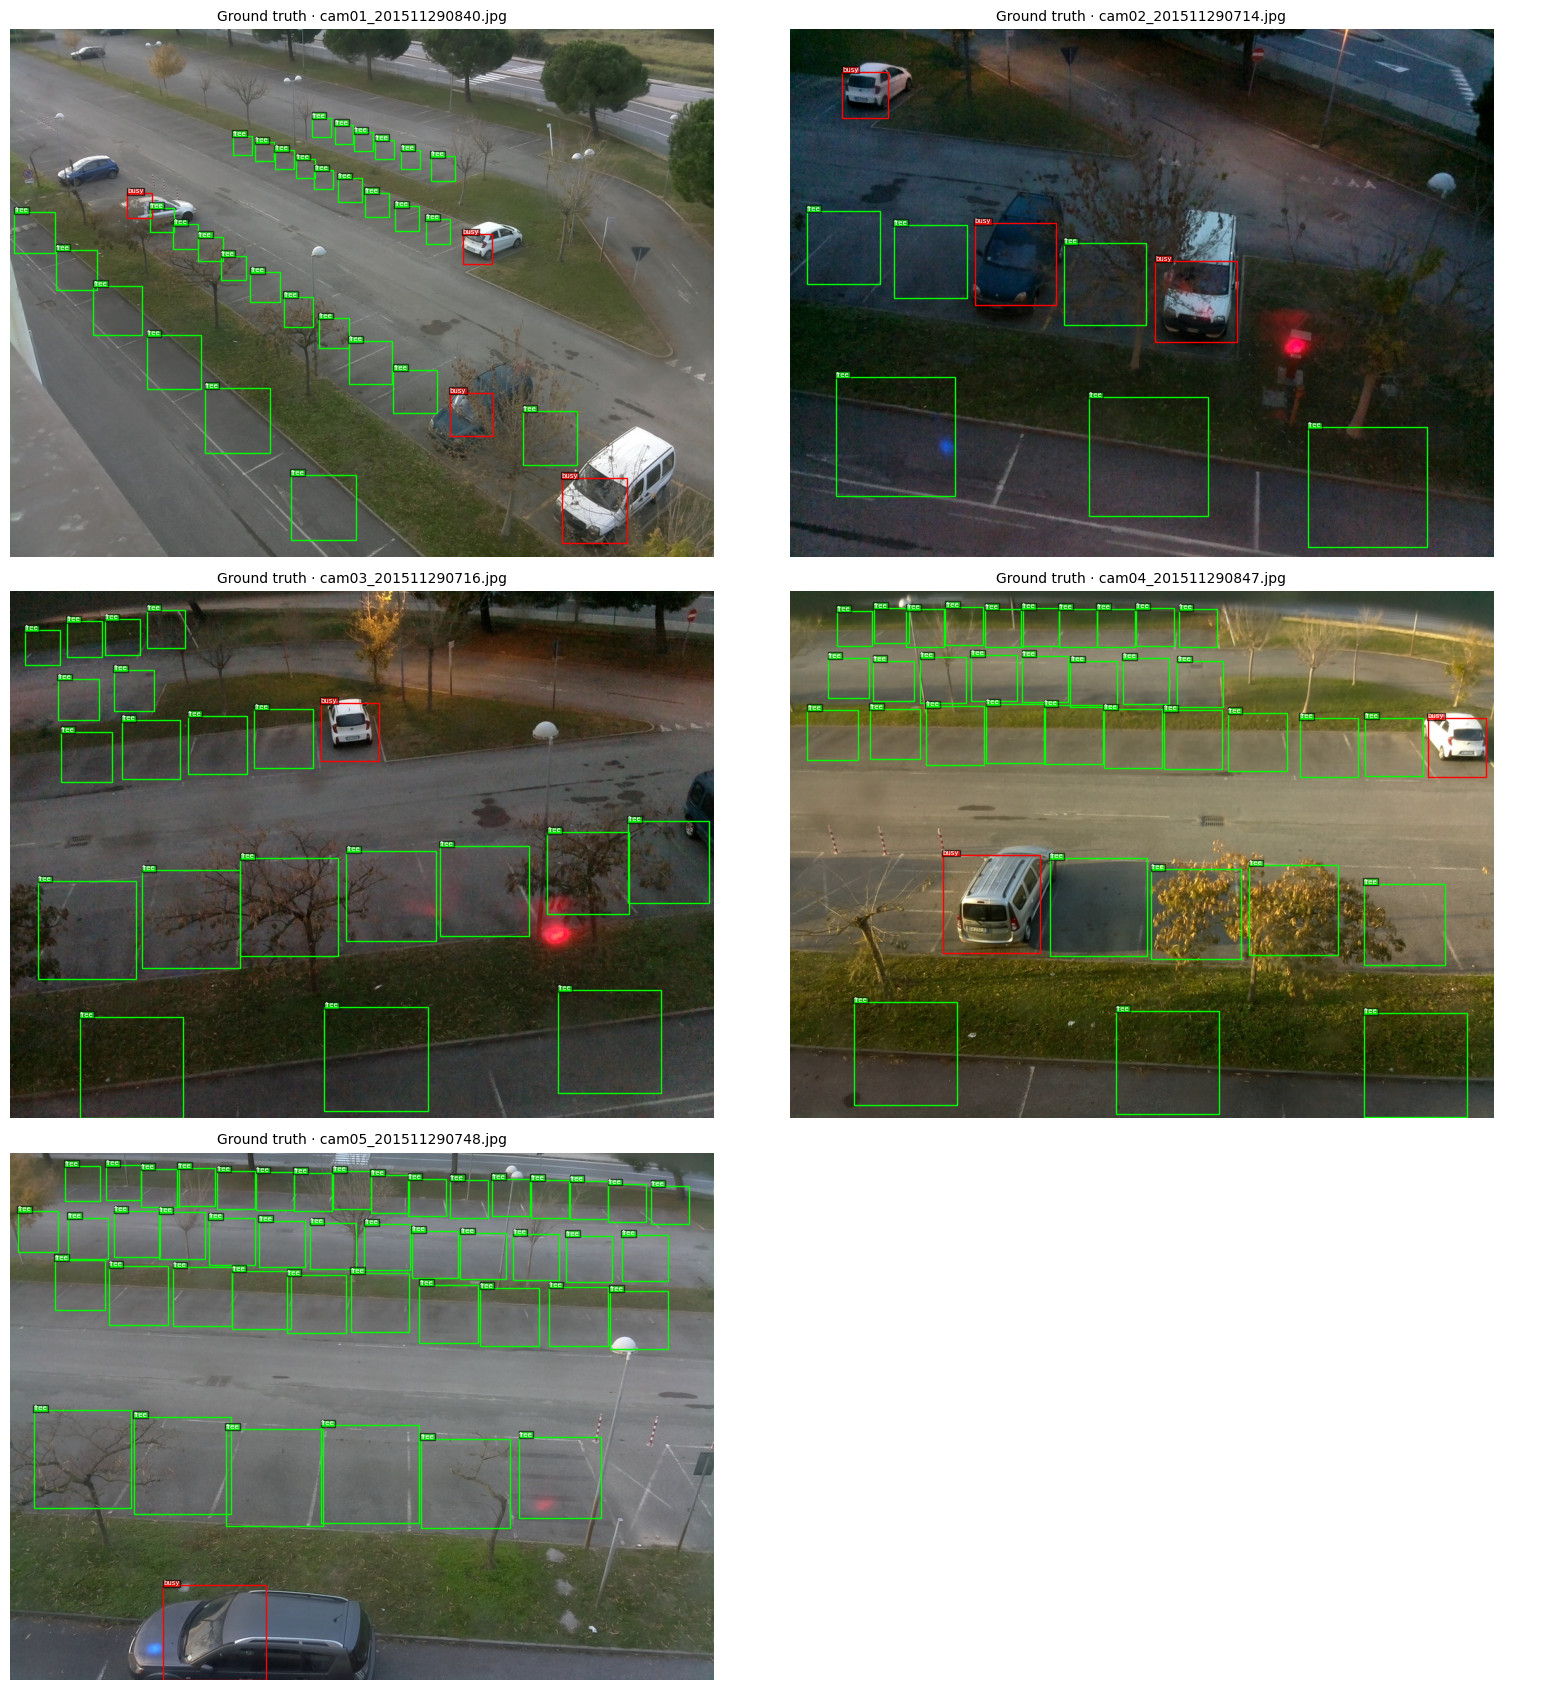

In [5]:
def draw_ground_truth(ax, path, label):
    image=Image.open(path).convert("RGB"); w,h=image.size
    ax.imshow(image); ax.axis("off")
    for line in label.read_text().splitlines():
        cls,cx,cy,bw,bh=map(float,line.split())
        color="lime" if cls==0 else "red"
        ax.add_patch(Rectangle(((cx-bw/2)*w,(cy-bh/2)*h),bw*w,bh*h,fill=False,edgecolor=color,linewidth=1))
        ax.text((cx-bw/2)*w,(cy-bh/2)*h,"free" if cls==0 else "busy",fontsize=5,color="white",bbox={"facecolor":color,"alpha":.6,"pad":.3})
# Five different cameras to inspect foreground, distant, empty and occupied spaces.
examples=[]; cameras=set()
for r in manifest:
    if r["split"]=="train" and r["camera"] not in cameras:
        cameras.add(r["camera"]);examples.append(r)
    if len(examples)==5:break
fig,axes=plt.subplots(3,2,figsize=(16,17))
for ax,r in zip(axes.flat,examples):
    draw_ground_truth(ax,DATA/"images"/"train"/r["file"],DATA/"labels"/"train"/(Path(r["file"]).stem+".txt"))
    ax.set_title("Ground truth · "+r["file"],fontsize=10)
axes.flat[-1].axis("off");plt.tight_layout();plt.show()

## 3. Baseline и три независимых изменения
E0 — baseline; каждый из E1–E3 меняет ровно один гиперпараметр относительно E0. Аугментация одинакова во всех запусках.

| Run | Image size | Learning rate | Batch | Изменение |
|---|---:|---:|---:|---|
| E0 | 640 | 0.001 | 8 | Baseline |
| E1 | 640 | 0.0003 | 8 | Learning rate |
| E2 | 800 | 0.001 | 8 | Image size |
| E3 | 640 | 0.001 | 4 | Batch size |

**Гипотезы до результатов:** меньший LR может сделать дообучение стабильнее, но замедлить его; размер 800 может помочь мелким местам за счёт детализации; меньший batch меняет шум градиента и расход памяти.

Общие условия: YOLO11n, официальные yolo11n.pt, seed 1409, AdamW, 10 эпох. Оптимизатор задан явно, чтобы lr0 применялся. Warmup — 1 эпоха; LR линейно снижается до 10% начального. Mosaic=1.0 и close_mosaic=0 одинаковы во всех запусках: аугментация не является переменной эксперимента.

Для прозрачного сравнения batch используем nbs=1 (без накопления градиентов) и weight_decay=0 во всех запусках: библиотека не меняет накопление и регуляризацию при переходе 8→4. E3 делает больше обновлений за эпоху; одинаковые 10 эпох не означают одинаковое число шагов оптимизатора.

Выбор настройки — по validation mAP@0.50:0.95. Один seed и 10 эпох дают сравнение при ограниченном бюджете, а не доказательство универсального превосходства.

**Recovery note:** baseline was interrupted after epoch 6 when the generated input directory was rebuilt by another session. It was resumed with optimizer state on the same data, using a private snapshot. Reported duration sums completed training segments. Fresh runs train from the same initial checkpoint; exact bitwise reproduction across hardware or interruption is not claimed.

In [6]:
EXPERIMENTS = [
    {"name":"E0_baseline", "imgsz":640, "lr0":0.001, "batch":8, "mosaic":1.0},
    {"name":"E1_learning_rate", "imgsz":640, "lr0":0.0003, "batch":8, "mosaic":1.0},
    {"name":"E2_image_size", "imgsz":800, "lr0":0.001, "batch":8, "mosaic":1.0},
    {"name":"E3_batch_size", "imgsz":640, "lr0":0.001, "batch":4, "mosaic":1.0},
]
display(pd.DataFrame(EXPERIMENTS).assign(epochs=EPOCHS,optimizer="AdamW"))
runs=[]
RUN_DIR.mkdir(exist_ok=True)
# Use a private snapshot so a separate data-preparation session cannot delete active images.
SNAPSHOT = RUN_DIR / "data_snapshot"
if not (SNAPSHOT / "manifest.csv").exists():
    shutil.copytree(DATA, SNAPSHOT, dirs_exist_ok=True)
assert (SNAPSHOT / "manifest.csv").read_bytes() == (DATA / "manifest.csv").read_bytes()
DATA = SNAPSHOT
DATA_YAML = DATA / "dataset.yaml"
DATA_YAML.write_text(f"path: {DATA.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: free\n  1: busy\n")
DATA_YAML = configure_dataset(DATA, manifest)

def metric_dict(m):
    return {"precision":float(m.box.mp),"recall":float(m.box.mr),"map50":float(m.box.map50),"map50_95":float(m.box.map)}
def release_memory():
    gc.collect()
    if DEVICE=="mps":torch.mps.empty_cache()
    elif torch.cuda.is_available():torch.cuda.empty_cache()
def run_experiment(exp):
    if not RUN_TRAINING:return
    result_file=RUN_DIR/exp["name"]/"completed.json"
    if result_file.exists():
        result=json.loads(result_file.read_text())
        assert result["epochs"]==EPOCHS and result["imgsz"]==exp["imgsz"] and result["lr0"]==exp["lr0"]
        runs.append(result);print("Reusing completed run:",exp["name"]);return
    release_memory()
    # Fresh experiments use the same pretrained checkpoint. Recover interrupted epochs if present.
    last_path = RUN_DIR / exp["name"] / "weights" / "last.pt"
    prior_seconds = 0.0
    resumed_from_epoch = 0
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location="cpu", weights_only=False)
        resumed_from_epoch = int(checkpoint.get("epoch", -1)) + 1
        assert resumed_from_epoch < EPOCHS and checkpoint.get("optimizer") is not None
        prior_history = pd.read_csv(last_path.parents[1] / "results.csv")
        prior_seconds = float(prior_history.iloc[-1]["time"])
        del checkpoint
    model=YOLO(str(last_path) if resumed_from_epoch else "yolo11n.pt")
    def progress(trainer):
        (RUN_DIR/"progress.json").write_text(json.dumps({"run":exp["name"],"epoch":min(trainer.epoch+1,EPOCHS),"total":EPOCHS,"time":time.time()}))
        print(f"COMPLETED EPOCH {min(trainer.epoch+1,EPOCHS)}/{EPOCHS}: {exp['name']}")
    model.add_callback("on_fit_epoch_end",progress)
    started=time.perf_counter()
    model.train(resume=bool(resumed_from_epoch),data=str(DATA_YAML),epochs=EPOCHS,imgsz=exp["imgsz"],batch=exp["batch"],
                optimizer="AdamW",lr0=exp["lr0"],lrf=.1,warmup_epochs=1.0,
                cos_lr=False,close_mosaic=0,mosaic=exp["mosaic"],nbs=1,weight_decay=0.0,seed=SEED,deterministic=True,patience=100,
                workers=0,device=DEVICE,cache=False,plots=False,save=True,
                project=str(RUN_DIR),name=exp["name"],exist_ok=True,verbose=False)
    seconds=prior_seconds + time.perf_counter()-started
    path=RUN_DIR/exp["name"]
    del model;release_memory()
    best=YOLO(str(path/"weights"/"best.pt"))
    val=best.val(data=str(DATA_YAML),split="val",imgsz=exp["imgsz"],batch=exp["batch"],
                 device=DEVICE,workers=0,conf=.001,iou=.7,plots=False,
                 project=str(RUN_DIR),name=exp["name"]+"_val",exist_ok=True,verbose=False)
    history=pd.read_csv(path/"results.csv")
    result={**exp,"epochs":EPOCHS,"batch":exp["batch"],"optimizer":"AdamW","seed":SEED,
            "training_seconds":seconds,"resumed_from_epoch":resumed_from_epoch,"validation":metric_dict(val),
            "history":history.to_dict(orient="records"),"configuration":yaml.safe_load((path/"args.yaml").read_text()),
            "weights":str(path/"weights"/"best.pt")}
    result_file.write_text(json.dumps(result,indent=2,default=str))
    runs.append(result)
    display(pd.DataFrame([{**exp,"minutes":seconds/60,**result["validation"]}]).round(4))
    del best,val;release_memory()

,name,imgsz,lr0,batch,mosaic,epochs,optimizer
0,E0_baseline,640,0.0010,8,1.0,10,AdamW
1,E1_learning_rate,640,0.0003,8,1.0,10,AdamW
2,E2_image_size,800,0.0010,8,1.0,10,AdamW
3,E3_batch_size,640,0.0010,4,1.0,10,AdamW


In [7]:
run_experiment(EXPERIMENTS[0])

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.218 🚀 Python-3.13.9 torch-2.15.0 MPS (Apple M1)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E0_baseline/weights/last.pt, momentum=0.937, mosai


                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (674 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 5.1it/s 7.1s

                   all        288      10371      0.976      0.943      0.987      0.712


Speed: 0.3ms preprocess, 2.1ms inference, 0.0ms loss, 12.8ms postprocess per image


,name,imgsz,lr0,batch,mosaic,minutes,precision,recall,map50,map50_95
0,E0_baseline,640,0.001,8,1.0,22.8586,0.9759,0.943,0.9868,0.7121


In [8]:
run_experiment(EXPERIMENTS[1])

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.218 🚀 Python-3.13.9 torch-2.15.0 MPS (Apple M1)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E1_learning_rate, nbs=1, nms=None, opset=None, optimize=False, opt

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,528 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.7it/s 9.7s

                   all        288      10371      0.974      0.935      0.985      0.708


Speed: 0.4ms preprocess, 3.2ms inference, 0.0ms loss, 15.3ms postprocess per image


,name,imgsz,lr0,batch,mosaic,minutes,precision,recall,map50,map50_95
0,E1_learning_rate,640,0.0003,8,1.0,27.5206,0.9736,0.935,0.9847,0.7084


In [9]:
run_experiment(EXPERIMENTS[2])

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.218 🚀 Python-3.13.9 torch-2.15.0 MPS (Apple M1)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E2_image_size, nbs=1, nms=None, opset=None, optimize=False, optimiz

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,561 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 4.0it/s 9.0s

                   all        288      10371      0.976      0.967      0.992      0.762


Speed: 0.3ms preprocess, 2.2ms inference, 0.0ms loss, 17.5ms postprocess per image


,name,imgsz,lr0,batch,mosaic,minutes,precision,recall,map50,map50_95
0,E2_image_size,800,0.001,8,1.0,58.9852,0.9756,0.9666,0.9917,0.7621


In [10]:
run_experiment(EXPERIMENTS[3])

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.218 🚀 Python-3.13.9 torch-2.15.0 MPS (Apple M1)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E3_batch_size, nbs=1, nms=None, opset=None, optimize=False, optimiz

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (2,950 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 72/72 8.9it/s 8.1s

                   all        288      10371      0.975      0.949      0.989      0.712


Speed: 0.5ms preprocess, 3.9ms inference, 0.0ms loss, 13.3ms postprocess per image


,name,imgsz,lr0,batch,mosaic,minutes,precision,recall,map50,map50_95
0,E3_batch_size,640,0.001,4,1.0,20.8917,0.9752,0.949,0.989,0.7124


## 4. Сравнение на validation
Precision характеризует ложные обнаружения, recall — пропуски. AP — площадь под precision–recall кривой; mAP усредняет AP по классам. mAP50 требует IoU ≥0.50, mAP50:95 усредняет требования IoU от 0.50 до 0.95. Это метрики детекции, а не accuracy изображений.

Основной критерий задан до запуска: mAP50:95 на validation. Тестовые метрики не используются для выбора гиперпараметров.

,name,imgsz,lr0,batch,mosaic,minutes,precision,recall,map50,map50_95
0,E0_baseline,640,0.0010,8,1.0,22.85862,0.97591,0.94295,0.98684,0.71212
1,E1_learning_rate,640,0.0003,8,1.0,27.52064,0.97362,0.93504,0.98468,0.70841
2,E2_image_size,800,0.0010,8,1.0,58.98518,0.97558,0.96664,0.99171,0.76207
3,E3_batch_size,640,0.0010,4,1.0,20.89169,0.97520,0.94899,0.98899,0.71241


Selected using validation mAP50:95: E2_image_size


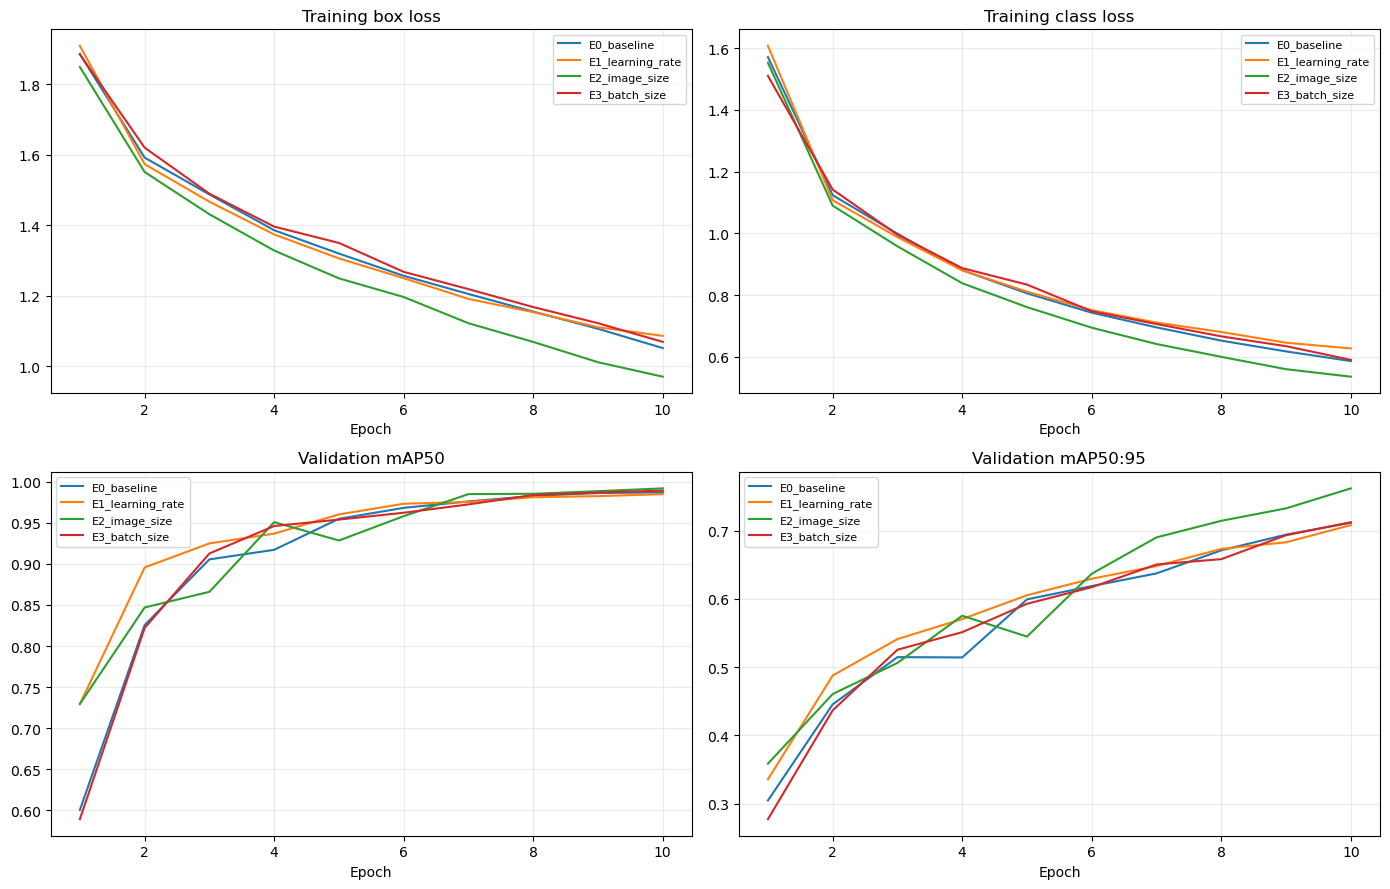

**Changes from E0 in percentage points (training time remains in minutes):**

,name,imgsz,lr0,batch,mosaic,minutes,precision,recall,map50,map50_95
0,E0_baseline,640,0.001,8,1.0,22.859,0.000,0.000,0.000,0.000
1,E1_learning_rate,640,0.000,8,1.0,27.521,-0.229,-0.791,-0.215,-0.371
2,E2_image_size,800,0.001,8,1.0,58.985,-0.034,2.369,0.487,4.995
3,E3_batch_size,640,0.001,4,1.0,20.892,-0.071,0.603,0.215,0.028


<details><summary>Reproducibility: configurations and full epoch histories</summary>

```json
[
  {
    "name": "E0_baseline",
    "imgsz": 640,
    "lr0": 0.001,
    "batch": 8,
    "mosaic": 1.0,
    "epochs": 10,
    "optimizer": "AdamW",
    "seed": 1409,
    "training_seconds": 1371.5169589590005,
    "resumed_from_epoch": 6,
    "validation": {
      "precision": 0.9759140997822997,
      "recall": 0.9429513304958697,
      "map50": 0.9868353597444146,
      "map50_95": 0.7121247839626497
    },
    "history": [
      {
        "epoch": 1,
        "time": 115.94,
        "train/box_loss": 1.88514,
        "train/cls_loss": 1.57129,
        "train/dfl_loss": 1.35725,
        "metrics/precision(B)": 0.86341,
        "metrics/recall(B)": 0.51785,
        "metrics/mAP50(B)": 0.60063,
        "metrics/mAP50-95(B)": 0.30443,
        "val/box_loss": 1.77348,
        "val/cls_loss": 1.47188,
        "val/dfl_loss": 1.35451,
        "lr/pg0": 0.000991736,
        "lr/pg1": 0.000991736,
        "lr/pg2": 0.00181818
      },
      {
        "epoch": 2,
        "time": 225.778,
        "train/box_loss": 1.59147,
        "train/cls_loss": 1.12356,
        "train/dfl_loss": 1.18663,
        "metrics/precision(B)": 0.83914,
        "metrics/recall(B)": 0.73956,
        "metrics/mAP50(B)": 0.8255,
        "metrics/mAP50-95(B)": 0.44539,
        "val/box_loss": 1.63297,
        "val/cls_loss": 1.14221,
        "val/dfl_loss": 1.22663,
        "lr/pg0": 0.00091,
        "lr/pg1": 0.00091,
        "lr/pg2": 0.00091
      },
      {
        "epoch": 3,
        "time": 359.974,
        "train/box_loss": 1.487,
        "train/cls_loss": 0.99885,
        "train/dfl_loss": 1.13406,
        "metrics/precision(B)": 0.93517,
        "metrics/recall(B)": 0.79264,
        "metrics/mAP50(B)": 0.90534,
        "metrics/mAP50-95(B)": 0.51461,
        "val/box_loss": 1.48191,
        "val/cls_loss": 0.99541,
        "val/dfl_loss": 1.15068,
        "lr/pg0": 0.00082,
        "lr/pg1": 0.00082,
        "lr/pg2": 0.00082
      },
      {
        "epoch": 4,
        "time": 539.484,
        "train/box_loss": 1.38563,
        "train/cls_loss": 0.88053,
        "train/dfl_loss": 1.08641,
        "metrics/precision(B)": 0.91001,
        "metrics/recall(B)": 0.82973,
        "metrics/mAP50(B)": 0.91701,
        "metrics/mAP50-95(B)": 0.51419,
        "val/box_loss": 1.44695,
        "val/cls_loss": 0.89675,
        "val/dfl_loss": 1.12104,
        "lr/pg0": 0.00073,
        "lr/pg1": 0.00073,
        "lr/pg2": 0.00073
      },
      {
        "epoch": 5,
        "time": 687.585,
        "train/box_loss": 1.31938,
        "train/cls_loss": 0.8055,
        "train/dfl_loss": 1.05733,
        "metrics/precision(B)": 0.95608,
        "metrics/recall(B)": 0.87397,
        "metrics/mAP50(B)": 0.95472,
        "metrics/mAP50-95(B)": 0.59931,
        "val/box_loss": 1.2854,
        "val/cls_loss": 0.72793,
        "val/dfl_loss": 1.05845,
        "lr/pg0": 0.00064,
        "lr/pg1": 0.00064,
        "lr/pg2": 0.00064
      },
      {
        "epoch": 6,
        "time": 895.197,
        "train/box_loss": 1.25641,
        "train/cls_loss": 0.74265,
        "train/dfl_loss": 1.03016,
        "metrics/precision(B)": 0.94738,
        "metrics/recall(B)": 0.90599,
        "metrics/mAP50(B)": 0.96801,
        "metrics/mAP50-95(B)": 0.6188,
        "val/box_loss": 1.26216,
        "val/cls_loss": 0.68194,
        "val/dfl_loss": 1.05206,
        "lr/pg0": 0.00055,
        "lr/pg1": 0.00055,
        "lr/pg2": 0.00055
      },
      {
        "epoch": 7,
        "time": 113.43,
        "train/box_loss": 1.20488,
        "train/cls_loss": 0.69507,
        "train/dfl_loss": 1.01423,
        "metrics/precision(B)": 0.96389,
        "metrics/recall(B)": 0.92755,
        "metrics/mAP50(B)": 0.97586,
        "metrics/mAP50-95(B)": 0.63741,
        "val/box_loss": 1.18135,
        "val/cls_loss": 0.62422,
        "val/dfl_loss": 1.00592,
        "lr/pg0": 0.00046,
        "lr/pg1": 0.00046,
        "lr/pg2": 0.00046
      },
      {
        "epoch": 8,
        "time": 230.333,
        "train/box_loss": 1.15483,
        "train/cls_loss": 0.65211,
        "train/dfl_loss": 0.9923,
        "metrics/precision(B)": 0.96731,
        "metrics/recall(B)": 0.92297,
        "metrics/mAP50(B)": 0.98251,
        "metrics/mAP50-95(B)": 0.67125,
        "val/box_loss": 1.11224,
        "val/cls_loss": 0.57068,
        "val/dfl_loss": 0.98325,
        "lr/pg0": 0.00037,
        "lr/pg1": 0.00037,
        "lr/pg2": 0.00037
      },
      {
        "epoch": 9,
        "time": 343.913,
        "train/box_loss": 1.10622,
        "train/cls_loss": 0.61714,
        "train/dfl_loss": 0.9761,
        "metrics/precision(B)": 0.97029,
        "metrics/recall(B)": 0.94111,
        "metrics/mAP50(B)": 0.98604,
        "metrics/mAP50-95(B)": 0.69422,
        "val/box_loss": 1.04662,
        "val/cls_loss": 0.55075,
        "val/dfl_loss": 0.96056,
        "lr/pg0": 0.00028,
        "lr/pg1": 0.00028,
        "lr/pg2": 0.00028
      },
      {
        "epoch": 10,
        "time": 458.289,
        "train/box_loss": 1.05148,
        "train/cls_loss": 0.58596,
        "train/dfl_loss": 0.95914,
        "metrics/precision(B)": 0.97613,
        "metrics/recall(B)": 0.94271,
        "metrics/mAP50(B)": 0.98687,
        "metrics/mAP50-95(B)": 0.71172,
        "val/box_loss": 1.00131,
        "val/cls_loss": 0.50753,
        "val/dfl_loss": 0.9457,
        "lr/pg0": 0.00019,
        "lr/pg1": 0.00019,
        "lr/pg2": 0.00019
      }
    ],
    "configuration": {
      "task": "detect",
      "mode": "train",
      "model": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E0_baseline/weights/last.pt",
      "data": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml",
      "epochs": 10,
      "time": null,
      "patience": 100,
      "batch": 8,
      "imgsz": 640,
      "save": true,
      "save_period": -1,
      "cache": false,
      "device": "mps",
      "workers": 0,
      "project": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run",
      "name": "E0_baseline",
      "exist_ok": true,
      "pretrained": true,
      "cls_remap": true,
      "optimizer": "AdamW",
      "verbose": false,
      "seed": 1409,
      "deterministic": true,
      "single_cls": false,
      "rect": false,
      "cos_lr": false,
      "close_mosaic": 0,
      "resume": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E0_baseline/weights/last.pt",
      "amp": true,
      "fraction": 1.0,
      "profile": false,
      "freeze": null,
      "multi_scale": 0.0,
      "compile": false,
      "channels_last": null,
      "overlap_mask": true,
      "mask_ratio": 4,
      "dropout": 0.0,
      "val": true,
      "split": "val",
      "save_json": false,
      "conf": null,
      "iou": null,
      "max_det": 300,
      "quantize": null,
      "dnn": false,
      "plots": false,
      "nms": null,
      "tile": false,
      "tile_overlap": 0.2,
      "source": null,
      "vid_stride": 1,
      "stream_buffer": false,
      "visualize": false,
      "augment": false,
      "agnostic_nms": false,
      "classes": null,
      "retina_masks": false,
      "embed": null,
      "show": false,
      "save_frames": false,
      "save_txt": false,
      "save_conf": false,
      "save_crop": false,
      "show_labels": true,
      "show_conf": true,
      "show_boxes": true,
      "line_width": null,
      "format": "torchscript",
      "optimize": false,
      "dynamic": false,
      "simplify": true,
      "opset": null,
      "workspace": null,
      "lr0": 0.001,
      "lrf": 0.1,
      "momentum": 0.937,
      "weight_decay": 0.0,
      "warmup_epochs": 1.0,
      "warmup_momentum": 0.8,
      "warmup_bias_lr": 0.1,
      "distill_model": null,
      "dis": 6.0,
      "box": 7.5,
      "cls": 0.5,
      "cls_pw": 0.0,
      "dfl": 1.5,
      "pose": 12.0,
      "kobj": 1.0,
      "rle": 1.0,
      "angle": 1.0,
      "dlog": 1.0,
      "dgrad": 0.5,
      "dlam": 1.0,
      "nbs": 1,
      "hsv_h": 0.015,
      "hsv_s": 0.7,
      "hsv_v": 0.4,
      "degrees": 0.0,
      "translate": 0.1,
      "scale": 0.5,
      "shear": 0.0,
      "perspective": 0.0,
      "flipud": 0.0,
      "fliplr": 0.5,
      "bgr": 0.0,
      "mosaic": 1.0,
      "mixup": 0.0,
      "cutmix": 0.0,
      "copy_paste": 0.0,
      "copy_paste_mode": "flip",
      "auto_augment": "randaugment",
      "erasing": 0.4,
      "cfg": null,
      "tracker": "tracktrack.yaml",
      "save_dir": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E0_baseline"
    },
    "weights": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E0_baseline/weights/best.pt"
  },
  {
    "name": "E1_learning_rate",
    "imgsz": 640,
    "lr0": 0.0003,
    "batch": 8,
    "mosaic": 1.0,
    "epochs": 10,
    "optimizer": "AdamW",
    "seed": 1409,
    "training_seconds": 1651.2384295420015,
    "resumed_from_epoch": 0,
    "validation": {
      "precision": 0.9736215308807015,
      "recall": 0.9350421912773301,
      "map50": 0.9846822464952867,
      "map50_95": 0.7084098753039387
    },
    "history": [
      {
        "epoch": 1,
        "time": 128.511,
        "train/box_loss": 1.9082,
        "train/cls_loss": 1.60775,
        "train/dfl_loss": 1.36225,
        "metrics/precision(B)": 0.82359,
        "metrics/recall(B)": 0.62949,
        "metrics/mAP50(B)": 0.72951,
        "metrics/mAP50-95(B)": 0.33548,
        "val/box_loss": 2.05605,
        "val/cls_loss": 1.4797,
        "val/dfl_loss": 1.36773,
        "lr/pg0": 0.000297521,
        "lr/pg1": 0.000297521,
        "lr/pg2": 0.00112397
      },
      {
        "epoch": 2,
        "time": 244.732,
        "train/box_loss": 1.57297,
        "train/cls_loss": 1.10728,
        "train/dfl_loss": 1.15932,
        "metrics/precision(B)": 0.9206,
        "metrics/recall(B)": 0.77088,
        "metrics/mAP50(B)": 0.89556,
        "metrics/mAP50-95(B)": 0.48769,
        "val/box_loss": 1.55785,
        "val/cls_loss": 1.10919,
        "val/dfl_loss": 1.16427,
        "lr/pg0": 0.000273,
        "lr/pg1": 0.000273,
        "lr/pg2": 0.000273
      },
      {
        "epoch": 3,
        "time": 360.776,
        "train/box_loss": 1.46639,
        "train/cls_loss": 0.98765,
        "train/dfl_loss": 1.10926,
        "metrics/precision(B)": 0.92077,
        "metrics/recall(B)": 0.85168,
        "metrics/mAP50(B)": 0.92479,
        "metrics/mAP50-95(B)": 0.54112,
        "val/box_loss": 1.41953,
        "val/cls_loss": 0.94826,
        "val/dfl_loss": 1.11507,
        "lr/pg0": 0.000246,
        "lr/pg1": 0.000246,
        "lr/pg2": 0.000246
      },
      {
        "epoch": 4,
        "time": 488.467,
        "train/box_loss": 1.37364,
        "train/cls_loss": 0.87997,
        "train/dfl_loss": 1.07001,
        "metrics/precision(B)": 0.91703,
        "metrics/recall(B)": 0.85769,
        "metrics/mAP50(B)": 0.93667,
        "metrics/mAP50-95(B)": 0.57048,
        "val/box_loss": 1.34005,
        "val/cls_loss": 0.84282,
        "val/dfl_loss": 1.07568,
        "lr/pg0": 0.000219,
        "lr/pg1": 0.000219,
        "lr/pg2": 0.000219
      },
      {
        "epoch": 5,
        "time": 635.134,
        "train/box_loss": 1.30577,
        "train/cls_loss": 0.81096,
        "train/dfl_loss": 1.04034,
        "metrics/precision(B)": 0.94873,
        "metrics/recall(B)": 0.86283,
        "metrics/mAP50(B)": 0.96007,
        "metrics/mAP50-95(B)": 0.60538,
        "val/box_loss": 1.26676,
        "val/cls_loss": 0.75929,
        "val/dfl_loss": 1.03798,
        "lr/pg0": 0.000192,
        "lr/pg1": 0.000192,
        "lr/pg2": 0.000192
      },
      {
        "epoch": 6,
        "time": 819.312,
        "train/box_loss": 1.24959,
        "train/cls_loss": 0.75088,
        "train/dfl_loss": 1.01624,
        "metrics/precision(B)": 0.96434,
        "metrics/recall(B)": 0.91171,
        "metrics/mAP50(B)": 0.97304,
        "metrics/mAP50-95(B)": 0.62957,
        "val/box_loss": 1.23276,
        "val/cls_loss": 0.66337,
        "val/dfl_loss": 1.02592,
        "lr/pg0": 0.000165,
        "lr/pg1": 0.000165,
        "lr/pg2": 0.000165
      },
      {
        "epoch": 7,
        "time": 1014.23,
        "train/box_loss": 1.19091,
        "train/cls_loss": 0.71053,
        "train/dfl_loss": 0.99473,
        "metrics/precision(B)": 0.95773,
        "metrics/recall(B)": 0.91204,
        "metrics/mAP50(B)": 0.97517,
        "metrics/mAP50-95(B)": 0.64825,
        "val/box_loss": 1.18009,
        "val/cls_loss": 0.63592,
        "val/dfl_loss": 0.99951,
        "lr/pg0": 0.000138,
        "lr/pg1": 0.000138,
        "lr/pg2": 0.000138
      },
      {
        "epoch": 8,
        "time": 1230.35,
        "train/box_loss": 1.15333,
        "train/cls_loss": 0.68012,
        "train/dfl_loss": 0.98589,
        "metrics/precision(B)": 0.96667,
        "metrics/recall(B)": 0.92912,
        "metrics/mAP50(B)": 0.98094,
        "metrics/mAP50-95(B)": 0.67337,
        "val/box_loss": 1.10468,
        "val/cls_loss": 0.60024,
        "val/dfl_loss": 0.97168,
        "lr/pg0": 0.000111,
        "lr/pg1": 0.000111,
        "lr/pg2": 0.000111
      },
      {
        "epoch": 9,
        "time": 1459.61,
        "train/box_loss": 1.11062,
        "train/cls_loss": 0.64538,
        "train/dfl_loss": 0.97237,
        "metrics/precision(B)": 0.97332,
        "metrics/recall(B)": 0.92836,
        "metrics/mAP50(B)": 0.98226,
        "metrics/mAP50-95(B)": 0.68306,
        "val/box_loss": 1.09015,
        "val/cls_loss": 0.57002,
        "val/dfl_loss": 0.96631,
        "lr/pg0": 8.4e-05,
        "lr/pg1": 8.4e-05,
        "lr/pg2": 8.4e-05
      },
      {
        "epoch": 10,
        "time": 1639.73,
        "train/box_loss": 1.08611,
        "train/cls_loss": 0.62677,
        "train/dfl_loss": 0.96204,
        "metrics/precision(B)": 0.97416,
        "metrics/recall(B)": 0.93472,
        "metrics/mAP50(B)": 0.98468,
        "metrics/mAP50-95(B)": 0.70822,
        "val/box_loss": 1.02577,
        "val/cls_loss": 0.54156,
        "val/dfl_loss": 0.94328,
        "lr/pg0": 5.7e-05,
        "lr/pg1": 5.7e-05,
        "lr/pg2": 5.7e-05
      }
    ],
    "configuration": {
      "task": "detect",
      "mode": "train",
      "model": "yolo11n.pt",
      "data": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml",
      "epochs": 10,
      "time": null,
      "patience": 100,
      "batch": 8,
      "imgsz": 640,
      "save": true,
      "save_period": -1,
      "cache": false,
      "device": "mps",
      "workers": 0,
      "project": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run",
      "name": "E1_learning_rate",
      "exist_ok": true,
      "pretrained": true,
      "cls_remap": true,
      "optimizer": "AdamW",
      "verbose": false,
      "seed": 1409,
      "deterministic": true,
      "single_cls": false,
      "rect": false,
      "cos_lr": false,
      "close_mosaic": 0,
      "resume": false,
      "amp": true,
      "fraction": 1.0,
      "profile": false,
      "freeze": null,
      "multi_scale": 0.0,
      "compile": false,
      "channels_last": null,
      "overlap_mask": true,
      "mask_ratio": 4,
      "dropout": 0.0,
      "val": true,
      "split": "val",
      "save_json": false,
      "conf": null,
      "iou": null,
      "max_det": 300,
      "quantize": null,
      "dnn": false,
      "plots": false,
      "nms": null,
      "tile": false,
      "tile_overlap": 0.2,
      "source": null,
      "vid_stride": 1,
      "stream_buffer": false,
      "visualize": false,
      "augment": false,
      "agnostic_nms": false,
      "classes": null,
      "retina_masks": false,
      "embed": null,
      "show": false,
      "save_frames": false,
      "save_txt": false,
      "save_conf": false,
      "save_crop": false,
      "show_labels": true,
      "show_conf": true,
      "show_boxes": true,
      "line_width": null,
      "format": "torchscript",
      "optimize": false,
      "dynamic": false,
      "simplify": true,
      "opset": null,
      "workspace": null,
      "lr0": 0.0003,
      "lrf": 0.1,
      "momentum": 0.937,
      "weight_decay": 0.0,
      "warmup_epochs": 1.0,
      "warmup_momentum": 0.8,
      "warmup_bias_lr": 0.1,
      "distill_model": null,
      "dis": 6.0,
      "box": 7.5,
      "cls": 0.5,
      "cls_pw": 0.0,
      "dfl": 1.5,
      "pose": 12.0,
      "kobj": 1.0,
      "rle": 1.0,
      "angle": 1.0,
      "dlog": 1.0,
      "dgrad": 0.5,
      "dlam": 1.0,
      "nbs": 1,
      "hsv_h": 0.015,
      "hsv_s": 0.7,
      "hsv_v": 0.4,
      "degrees": 0.0,
      "translate": 0.1,
      "scale": 0.5,
      "shear": 0.0,
      "perspective": 0.0,
      "flipud": 0.0,
      "fliplr": 0.5,
      "bgr": 0.0,
      "mosaic": 1.0,
      "mixup": 0.0,
      "cutmix": 0.0,
      "copy_paste": 0.0,
      "copy_paste_mode": "flip",
      "auto_augment": "randaugment",
      "erasing": 0.4,
      "cfg": null,
      "tracker": "tracktrack.yaml",
      "save_dir": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E1_learning_rate"
    },
    "weights": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E1_learning_rate/weights/best.pt"
  },
  {
    "name": "E2_image_size",
    "imgsz": 800,
    "lr0": 0.001,
    "batch": 8,
    "mosaic": 1.0,
    "epochs": 10,
    "optimizer": "AdamW",
    "seed": 1409,
    "training_seconds": 3539.1107095000007,
    "resumed_from_epoch": 0,
    "validation": {
      "precision": 0.9755790214763149,
      "recall": 0.9666421588929381,
      "map50": 0.9917099934413818,
      "map50_95": 0.762072365781995
    },
    "history": [
      {
        "epoch": 1,
        "time": 435.772,
        "train/box_loss": 1.84831,
        "train/cls_loss": 1.55296,
        "train/dfl_loss": 1.39931,
        "metrics/precision(B)": 0.81235,
        "metrics/recall(B)": 0.66226,
        "metrics/mAP50(B)": 0.72953,
        "metrics/mAP50-95(B)": 0.35841,
        "val/box_loss": 1.76227,
        "val/cls_loss": 1.51178,
        "val/dfl_loss": 1.40796,
        "lr/pg0": 0.000991736,
        "lr/pg1": 0.000991736,
        "lr/pg2": 0.00181818
      },
      {
        "epoch": 2,
        "time": 769.512,
        "train/box_loss": 1.55062,
        "train/cls_loss": 1.08968,
        "train/dfl_loss": 1.21608,
        "metrics/precision(B)": 0.87181,
        "metrics/recall(B)": 0.75358,
        "metrics/mAP50(B)": 0.84686,
        "metrics/mAP50-95(B)": 0.46053,
        "val/box_loss": 1.55248,
        "val/cls_loss": 1.3639,
        "val/dfl_loss": 1.2663,
        "lr/pg0": 0.00091,
        "lr/pg1": 0.00091,
        "lr/pg2": 0.00091
      },
      {
        "epoch": 3,
        "time": 1109.47,
        "train/box_loss": 1.43086,
        "train/cls_loss": 0.95783,
        "train/dfl_loss": 1.15228,
        "metrics/precision(B)": 0.92159,
        "metrics/recall(B)": 0.76666,
        "metrics/mAP50(B)": 0.86593,
        "metrics/mAP50-95(B)": 0.50618,
        "val/box_loss": 1.45735,
        "val/cls_loss": 1.1006,
        "val/dfl_loss": 1.20243,
        "lr/pg0": 0.00082,
        "lr/pg1": 0.00082,
        "lr/pg2": 0.00082
      },
      {
        "epoch": 4,
        "time": 1497.41,
        "train/box_loss": 1.32804,
        "train/cls_loss": 0.83824,
        "train/dfl_loss": 1.10586,
        "metrics/precision(B)": 0.95673,
        "metrics/recall(B)": 0.87146,
        "metrics/mAP50(B)": 0.95061,
        "metrics/mAP50-95(B)": 0.57533,
        "val/box_loss": 1.32188,
        "val/cls_loss": 0.83557,
        "val/dfl_loss": 1.11209,
        "lr/pg0": 0.00073,
        "lr/pg1": 0.00073,
        "lr/pg2": 0.00073
      },
      {
        "epoch": 5,
        "time": 1931.69,
        "train/box_loss": 1.24914,
        "train/cls_loss": 0.7608,
        "train/dfl_loss": 1.07022,
        "metrics/precision(B)": 0.91037,
        "metrics/recall(B)": 0.83926,
        "metrics/mAP50(B)": 0.92832,
        "metrics/mAP50-95(B)": 0.54477,
        "val/box_loss": 1.45466,
        "val/cls_loss": 0.81135,
        "val/dfl_loss": 1.16517,
        "lr/pg0": 0.00064,
        "lr/pg1": 0.00064,
        "lr/pg2": 0.00064
      },
      {
        "epoch": 6,
        "time": 2266.73,
        "train/box_loss": 1.19623,
        "train/cls_loss": 0.69398,
        "train/dfl_loss": 1.04418,
        "metrics/precision(B)": 0.96635,
        "metrics/recall(B)": 0.89269,
        "metrics/mAP50(B)": 0.95792,
        "metrics/mAP50-95(B)": 0.63698,
        "val/box_loss": 1.1962,
        "val/cls_loss": 0.69547,
        "val/dfl_loss": 1.05861,
        "lr/pg0": 0.00055,
        "lr/pg1": 0.00055,
        "lr/pg2": 0.00055
      },
      {
        "epoch": 7,
        "time": 2500.34,
        "train/box_loss": 1.12193,
        "train/cls_loss": 0.64114,
        "train/dfl_loss": 1.0126,
        "metrics/precision(B)": 0.96671,
        "metrics/recall(B)": 0.94313,
        "metrics/mAP50(B)": 0.98473,
        "metrics/mAP50-95(B)": 0.69023,
        "val/box_loss": 1.07967,
        "val/cls_loss": 0.59437,
        "val/dfl_loss": 0.99975,
        "lr/pg0": 0.00046,
        "lr/pg1": 0.00046,
        "lr/pg2": 0.00046
      },
      {
        "epoch": 8,
        "time": 2810.89,
        "train/box_loss": 1.06893,
        "train/cls_loss": 0.59951,
        "train/dfl_loss": 0.99806,
        "metrics/precision(B)": 0.97146,
        "metrics/recall(B)": 0.94015,
        "metrics/mAP50(B)": 0.98513,
        "metrics/mAP50-95(B)": 0.71451,
        "val/box_loss": 1.00492,
        "val/cls_loss": 0.5332,
        "val/dfl_loss": 0.96841,
        "lr/pg0": 0.00037,
        "lr/pg1": 0.00037,
        "lr/pg2": 0.00037
      },
      {
        "epoch": 9,
        "time": 3283.46,
        "train/box_loss": 1.01147,
        "train/cls_loss": 0.55951,
        "train/dfl_loss": 0.97616,
        "metrics/precision(B)": 0.96894,
        "metrics/recall(B)": 0.95343,
        "metrics/mAP50(B)": 0.98833,
        "metrics/mAP50-95(B)": 0.73277,
        "val/box_loss": 0.98013,
        "val/cls_loss": 0.49199,
        "val/dfl_loss": 0.96183,
        "lr/pg0": 0.00028,
        "lr/pg1": 0.00028,
        "lr/pg2": 0.00028
      },
      {
        "epoch": 10,
        "time": 3526.13,
        "train/box_loss": 0.97045,
        "train/cls_loss": 0.53524,
        "train/dfl_loss": 0.96196,
        "metrics/precision(B)": 0.97581,
        "metrics/recall(B)": 0.96635,
        "metrics/mAP50(B)": 0.99171,
        "metrics/mAP50-95(B)": 0.76208,
        "val/box_loss": 0.89134,
        "val/cls_loss": 0.44779,
        "val/dfl_loss": 0.91857,
        "lr/pg0": 0.00019,
        "lr/pg1": 0.00019,
        "lr/pg2": 0.00019
      }
    ],
    "configuration": {
      "task": "detect",
      "mode": "train",
      "model": "yolo11n.pt",
      "data": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml",
      "epochs": 10,
      "time": null,
      "patience": 100,
      "batch": 8,
      "imgsz": 800,
      "save": true,
      "save_period": -1,
      "cache": false,
      "device": "mps",
      "workers": 0,
      "project": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run",
      "name": "E2_image_size",
      "exist_ok": true,
      "pretrained": true,
      "cls_remap": true,
      "optimizer": "AdamW",
      "verbose": false,
      "seed": 1409,
      "deterministic": true,
      "single_cls": false,
      "rect": false,
      "cos_lr": false,
      "close_mosaic": 0,
      "resume": false,
      "amp": true,
      "fraction": 1.0,
      "profile": false,
      "freeze": null,
      "multi_scale": 0.0,
      "compile": false,
      "channels_last": null,
      "overlap_mask": true,
      "mask_ratio": 4,
      "dropout": 0.0,
      "val": true,
      "split": "val",
      "save_json": false,
      "conf": null,
      "iou": null,
      "max_det": 300,
      "quantize": null,
      "dnn": false,
      "plots": false,
      "nms": null,
      "tile": false,
      "tile_overlap": 0.2,
      "source": null,
      "vid_stride": 1,
      "stream_buffer": false,
      "visualize": false,
      "augment": false,
      "agnostic_nms": false,
      "classes": null,
      "retina_masks": false,
      "embed": null,
      "show": false,
      "save_frames": false,
      "save_txt": false,
      "save_conf": false,
      "save_crop": false,
      "show_labels": true,
      "show_conf": true,
      "show_boxes": true,
      "line_width": null,
      "format": "torchscript",
      "optimize": false,
      "dynamic": false,
      "simplify": true,
      "opset": null,
      "workspace": null,
      "lr0": 0.001,
      "lrf": 0.1,
      "momentum": 0.937,
      "weight_decay": 0.0,
      "warmup_epochs": 1.0,
      "warmup_momentum": 0.8,
      "warmup_bias_lr": 0.1,
      "distill_model": null,
      "dis": 6.0,
      "box": 7.5,
      "cls": 0.5,
      "cls_pw": 0.0,
      "dfl": 1.5,
      "pose": 12.0,
      "kobj": 1.0,
      "rle": 1.0,
      "angle": 1.0,
      "dlog": 1.0,
      "dgrad": 0.5,
      "dlam": 1.0,
      "nbs": 1,
      "hsv_h": 0.015,
      "hsv_s": 0.7,
      "hsv_v": 0.4,
      "degrees": 0.0,
      "translate": 0.1,
      "scale": 0.5,
      "shear": 0.0,
      "perspective": 0.0,
      "flipud": 0.0,
      "fliplr": 0.5,
      "bgr": 0.0,
      "mosaic": 1.0,
      "mixup": 0.0,
      "cutmix": 0.0,
      "copy_paste": 0.0,
      "copy_paste_mode": "flip",
      "auto_augment": "randaugment",
      "erasing": 0.4,
      "cfg": null,
      "tracker": "tracktrack.yaml",
      "save_dir": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E2_image_size"
    },
    "weights": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E2_image_size/weights/best.pt"
  },
  {
    "name": "E3_batch_size",
    "imgsz": 640,
    "lr0": 0.001,
    "batch": 4,
    "mosaic": 1.0,
    "epochs": 10,
    "optimizer": "AdamW",
    "seed": 1409,
    "training_seconds": 1253.501386,
    "resumed_from_epoch": 0,
    "validation": {
      "precision": 0.975202053416452,
      "recall": 0.9489850428852571,
      "map50": 0.9889887989143351,
      "map50_95": 0.7124096825631476
    },
    "history": [
      {
        "epoch": 1,
        "time": 120.218,
        "train/box_loss": 1.88392,
        "train/cls_loss": 1.51038,
        "train/dfl_loss": 1.36299,
        "metrics/precision(B)": 0.53994,
        "metrics/recall(B)": 0.56908,
        "metrics/mAP50(B)": 0.58942,
        "metrics/mAP50-95(B)": 0.27701,
        "val/box_loss": 1.8375,
        "val/cls_loss": 1.63096,
        "val/dfl_loss": 1.36009,
        "lr/pg0": 0.000995868,
        "lr/pg1": 0.000995868,
        "lr/pg2": 0.00140909
      },
      {
        "epoch": 2,
        "time": 241.344,
        "train/box_loss": 1.61968,
        "train/cls_loss": 1.1419,
        "train/dfl_loss": 1.20845,
        "metrics/precision(B)": 0.83482,
        "metrics/recall(B)": 0.73635,
        "metrics/mAP50(B)": 0.82201,
        "metrics/mAP50-95(B)": 0.43666,
        "val/box_loss": 1.6398,
        "val/cls_loss": 1.53525,
        "val/dfl_loss": 1.26942,
        "lr/pg0": 0.00091,
        "lr/pg1": 0.00091,
        "lr/pg2": 0.00091
      },
      {
        "epoch": 3,
        "time": 361.722,
        "train/box_loss": 1.48905,
        "train/cls_loss": 0.99529,
        "train/dfl_loss": 1.14311,
        "metrics/precision(B)": 0.92009,
        "metrics/recall(B)": 0.81355,
        "metrics/mAP50(B)": 0.91254,
        "metrics/mAP50-95(B)": 0.52552,
        "val/box_loss": 1.39097,
        "val/cls_loss": 1.01482,
        "val/dfl_loss": 1.12006,
        "lr/pg0": 0.00082,
        "lr/pg1": 0.00082,
        "lr/pg2": 0.00082
      },
      {
        "epoch": 4,
        "time": 483.497,
        "train/box_loss": 1.39587,
        "train/cls_loss": 0.88712,
        "train/dfl_loss": 1.10023,
        "metrics/precision(B)": 0.92222,
        "metrics/recall(B)": 0.87112,
        "metrics/mAP50(B)": 0.94596,
        "metrics/mAP50-95(B)": 0.55124,
        "val/box_loss": 1.40929,
        "val/cls_loss": 0.92108,
        "val/dfl_loss": 1.11337,
        "lr/pg0": 0.00073,
        "lr/pg1": 0.00073,
        "lr/pg2": 0.00073
      },
      {
        "epoch": 5,
        "time": 604.742,
        "train/box_loss": 1.34959,
        "train/cls_loss": 0.83375,
        "train/dfl_loss": 1.0781,
        "metrics/precision(B)": 0.94683,
        "metrics/recall(B)": 0.87157,
        "metrics/mAP50(B)": 0.95374,
        "metrics/mAP50-95(B)": 0.59285,
        "val/box_loss": 1.31008,
        "val/cls_loss": 0.75616,
        "val/dfl_loss": 1.06429,
        "lr/pg0": 0.00064,
        "lr/pg1": 0.00064,
        "lr/pg2": 0.00064
      },
      {
        "epoch": 6,
        "time": 725.464,
        "train/box_loss": 1.26757,
        "train/cls_loss": 0.74741,
        "train/dfl_loss": 1.03756,
        "metrics/precision(B)": 0.9516,
        "metrics/recall(B)": 0.88585,
        "metrics/mAP50(B)": 0.96209,
        "metrics/mAP50-95(B)": 0.61717,
        "val/box_loss": 1.29036,
        "val/cls_loss": 0.67791,
        "val/dfl_loss": 1.05188,
        "lr/pg0": 0.00055,
        "lr/pg1": 0.00055,
        "lr/pg2": 0.00055
      },
      {
        "epoch": 7,
        "time": 852.333,
        "train/box_loss": 1.2186,
        "train/cls_loss": 0.70586,
        "train/dfl_loss": 1.02002,
        "metrics/precision(B)": 0.95409,
        "metrics/recall(B)": 0.92139,
        "metrics/mAP50(B)": 0.97223,
        "metrics/mAP50-95(B)": 0.65047,
        "val/box_loss": 1.14904,
        "val/cls_loss": 0.64061,
        "val/dfl_loss": 1.00302,
        "lr/pg0": 0.00046,
        "lr/pg1": 0.00046,
        "lr/pg2": 0.00046
      },
      {
        "epoch": 8,
        "time": 975.323,
        "train/box_loss": 1.16782,
        "train/cls_loss": 0.66591,
        "train/dfl_loss": 1.00625,
        "metrics/precision(B)": 0.96345,
        "metrics/recall(B)": 0.93107,
        "metrics/mAP50(B)": 0.98362,
        "metrics/mAP50-95(B)": 0.65833,
        "val/box_loss": 1.12987,
        "val/cls_loss": 0.57801,
        "val/dfl_loss": 0.98732,
        "lr/pg0": 0.00037,
        "lr/pg1": 0.00037,
        "lr/pg2": 0.00037
      },
      {
        "epoch": 9,
        "time": 1104.75,
        "train/box_loss": 1.12201,
        "train/cls_loss": 0.63417,
        "train/dfl_loss": 0.98853,
        "metrics/precision(B)": 0.95853,
        "metrics/recall(B)": 0.94688,
        "metrics/mAP50(B)": 0.98669,
        "metrics/mAP50-95(B)": 0.69338,
        "val/box_loss": 1.03436,
        "val/cls_loss": 0.53071,
        "val/dfl_loss": 0.9537,
        "lr/pg0": 0.00028,
        "lr/pg1": 0.00028,
        "lr/pg2": 0.00028
      },
      {
        "epoch": 10,
        "time": 1240.78,
        "train/box_loss": 1.06915,
        "train/cls_loss": 0.58973,
        "train/dfl_loss": 0.96664,
        "metrics/precision(B)": 0.97497,
        "metrics/recall(B)": 0.94888,
        "metrics/mAP50(B)": 0.989,
        "metrics/mAP50-95(B)": 0.71241,
        "val/box_loss": 1.01778,
        "val/cls_loss": 0.50114,
        "val/dfl_loss": 0.94827,
        "lr/pg0": 0.00019,
        "lr/pg1": 0.00019,
        "lr/pg2": 0.00019
      }
    ],
    "configuration": {
      "task": "detect",
      "mode": "train",
      "model": "yolo11n.pt",
      "data": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/dataset.yaml",
      "epochs": 10,
      "time": null,
      "patience": 100,
      "batch": 4,
      "imgsz": 640,
      "save": true,
      "save_period": -1,
      "cache": false,
      "device": "mps",
      "workers": 0,
      "project": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run",
      "name": "E3_batch_size",
      "exist_ok": true,
      "pretrained": true,
      "cls_remap": true,
      "optimizer": "AdamW",
      "verbose": false,
      "seed": 1409,
      "deterministic": true,
      "single_cls": false,
      "rect": false,
      "cos_lr": false,
      "close_mosaic": 0,
      "resume": false,
      "amp": true,
      "fraction": 1.0,
      "profile": false,
      "freeze": null,
      "multi_scale": 0.0,
      "compile": false,
      "channels_last": null,
      "overlap_mask": true,
      "mask_ratio": 4,
      "dropout": 0.0,
      "val": true,
      "split": "val",
      "save_json": false,
      "conf": null,
      "iou": null,
      "max_det": 300,
      "quantize": null,
      "dnn": false,
      "plots": false,
      "nms": null,
      "tile": false,
      "tile_overlap": 0.2,
      "source": null,
      "vid_stride": 1,
      "stream_buffer": false,
      "visualize": false,
      "augment": false,
      "agnostic_nms": false,
      "classes": null,
      "retina_masks": false,
      "embed": null,
      "show": false,
      "save_frames": false,
      "save_txt": false,
      "save_conf": false,
      "save_crop": false,
      "show_labels": true,
      "show_conf": true,
      "show_boxes": true,
      "line_width": null,
      "format": "torchscript",
      "optimize": false,
      "dynamic": false,
      "simplify": true,
      "opset": null,
      "workspace": null,
      "lr0": 0.001,
      "lrf": 0.1,
      "momentum": 0.937,
      "weight_decay": 0.0,
      "warmup_epochs": 1.0,
      "warmup_momentum": 0.8,
      "warmup_bias_lr": 0.1,
      "distill_model": null,
      "dis": 6.0,
      "box": 7.5,
      "cls": 0.5,
      "cls_pw": 0.0,
      "dfl": 1.5,
      "pose": 12.0,
      "kobj": 1.0,
      "rle": 1.0,
      "angle": 1.0,
      "dlog": 1.0,
      "dgrad": 0.5,
      "dlam": 1.0,
      "nbs": 1,
      "hsv_h": 0.015,
      "hsv_s": 0.7,
      "hsv_v": 0.4,
      "degrees": 0.0,
      "translate": 0.1,
      "scale": 0.5,
      "shear": 0.0,
      "perspective": 0.0,
      "flipud": 0.0,
      "fliplr": 0.5,
      "bgr": 0.0,
      "mosaic": 1.0,
      "mixup": 0.0,
      "cutmix": 0.0,
      "copy_paste": 0.0,
      "copy_paste_mode": "flip",
      "auto_augment": "randaugment",
      "erasing": 0.4,
      "cfg": null,
      "tracker": "tracktrack.yaml",
      "save_dir": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E3_batch_size"
    },
    "weights": "/Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/E3_batch_size/weights/best.pt"
  }
]
```
</details>

In [11]:
if RUN_TRAINING:
    comparison=pd.DataFrame([{k:r[k] for k in ("name","imgsz","lr0","batch","mosaic")} | {"minutes":r["training_seconds"]/60} | r["validation"] for r in runs])
    display(comparison.round(5))
    chosen=max(runs,key=lambda r:r["validation"]["map50_95"])
    print("Selected using validation mAP50:95:",chosen["name"])
    fig,axes=plt.subplots(2,2,figsize=(14,9))
    for run in runs:
        hist=pd.DataFrame(run["history"])
        for ax,key,title in zip(axes.flat,["train/box_loss","train/cls_loss","metrics/mAP50(B)","metrics/mAP50-95(B)"],["Training box loss","Training class loss","Validation mAP50","Validation mAP50:95"]):
            ax.plot(hist["epoch"],hist[key],label=run["name"]);ax.set(title=title,xlabel="Epoch");ax.grid(alpha=.25);ax.legend(fontsize=8)
    plt.tight_layout();plt.show()
    baseline=runs[0]["validation"]
    deltas=comparison.copy()
    for metric in ("precision","recall","map50","map50_95"):deltas[metric]=100*(deltas[metric]-baseline[metric])
    display(Markdown("**Changes from E0 in percentage points (training time remains in minutes):**"));display(deltas.round(3))
    # Persist all configurations and epoch logs inside this notebook's output.
    display(Markdown("<details><summary>Reproducibility: configurations and full epoch histories</summary>\n\n```json\n"+json.dumps(runs,indent=2,default=str)+"\n```\n</details>"))
else:
    saved=PROJECT/"model_metadata.json"
    if not saved.exists():urllib.request.urlretrieve(RELEASE+"/model_metadata.json",saved)
    chosen=json.loads(saved.read_text())["selected"]

## Measured interpretation

| Run | Change | Val P | Val R | Val mAP50 | Val mAP50:95 | Training minutes |
|---|---|---:|---:|---:|---:|---:|
| E0_baseline | Baseline | 0.9759 | 0.9430 | 0.9868 | 0.7121 | 22.9 |
| E1_learning_rate | Learning rate | 0.9736 | 0.9350 | 0.9847 | 0.7084 | 27.5 |
| E2_image_size | Image size | 0.9756 | 0.9666 | 0.9917 | 0.7621 | 59.0 |
| E3_batch_size | Batch size | 0.9752 | 0.9490 | 0.9890 | 0.7124 | 20.9 |

Selected using validation mAP50:95: **E2_image_size**.

| Test metric | Value |
|---|---:|
| precision | 0.9835 |
| recall | 0.9715 |
| map50 | 0.9928 |
| map50_95 | 0.7607 |

Measured validation mAP50:95 changes relative to E0: E1_learning_rate -0.37 percentage points, E2_image_size +4.99 percentage points, E3_batch_size +0.03 percentage points.

The winner is chosen only on validation. These results describe this single-seed, 10-epoch budget; they do not establish which setting would be best after full convergence or on another parking lot.

## 5. Финальный test: только выбранная модель
Ultralytics validation получает `conf=0.001` для сбора кандидатов и `iou=0.7` как порог NMS. Это не IoU правильного совпадения: mAP использует 0.50 и 0.50:0.95. Итоговые precision/recall рассчитываются библиотекой при пороге уверенности, выбранном по F1; они не соответствуют автоматически `conf=0.25` демо.

Предсказания и ручной аудит ниже используют фиксированные confidence 0.25 и NMS IoU 0.7. Эти настройки явно отличаются от процедуры mAP.

In [12]:
if RUN_TRAINING:
    shutil.copy2(chosen["weights"],FINAL_WEIGHTS)
else:
    if not FINAL_WEIGHTS.exists():urllib.request.urlretrieve(RELEASE+"/parking_yolo11n.pt",FINAL_WEIGHTS)
selected_model=YOLO(str(FINAL_WEIGHTS))
# Run test only after choosing a setting on validation.
test=selected_model.val(data=str(DATA_YAML),split="test",imgsz=int(chosen["imgsz"]),
                        batch=BATCH_SIZE,device=DEVICE,workers=0,conf=.001,iou=.7,
                        plots=False,project=str(RUN_DIR),name="selected_test",exist_ok=True,verbose=False)
test_metrics=metric_dict(test)
display(pd.DataFrame([{"selected":chosen["name"],**test_metrics}]).round(5))
print("Per-class AP50 and AP50:95:",dict(zip(test.names.values(),zip(test.box.ap50.tolist(),test.box.maps.tolist()))))

Ultralytics 8.4.218 🚀 Python-3.13.9 torch-2.15.0 MPS (Apple M1)


YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 769.6±108.0 MB/s, size: 290.8 KB)


val: Scanning /Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/labels/test... 334 images, 0 backgrounds, 0 corrupt: 96% ━━━━━━━━━━━╸ 334/347 1.0Kit/s 0.1s<0.0s

val: Scanning /Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/labels/test... 347 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 347/347 3.3Kit/s 0.1s

val: New cache created: /Users/alikhansagat/Desktop/Ali/DeepLearning/Project_Parking/.parking_four_run/data_snapshot/labels/test.cache


... (44 outputs left out)

                   all        347      12138      0.984      0.971      0.993      0.761


Speed: 0.4ms preprocess, 4.5ms inference, 0.0ms loss, 21.1ms postprocess per image


,selected,precision,recall,map50,map50_95
0,E2_image_size,0.98351,0.97145,0.99278,0.76071


Per-class AP50 and AP50:95: {'free': (0.9925840805053052, 0.7942628907873954), 'busy': (0.9929669082579958, 0.727148224095085)}


## 6. Пять тестовых предсказаний и подсчёт мест
Модель получает только изображение и предсказывает рамки, классы и уверенность. Координаты CSV нужны для обучения и оценки, не являются входом при новом предсказании. Количество мест — число оставшихся рамок каждого класса, отдельная регрессия количества не обучалась.

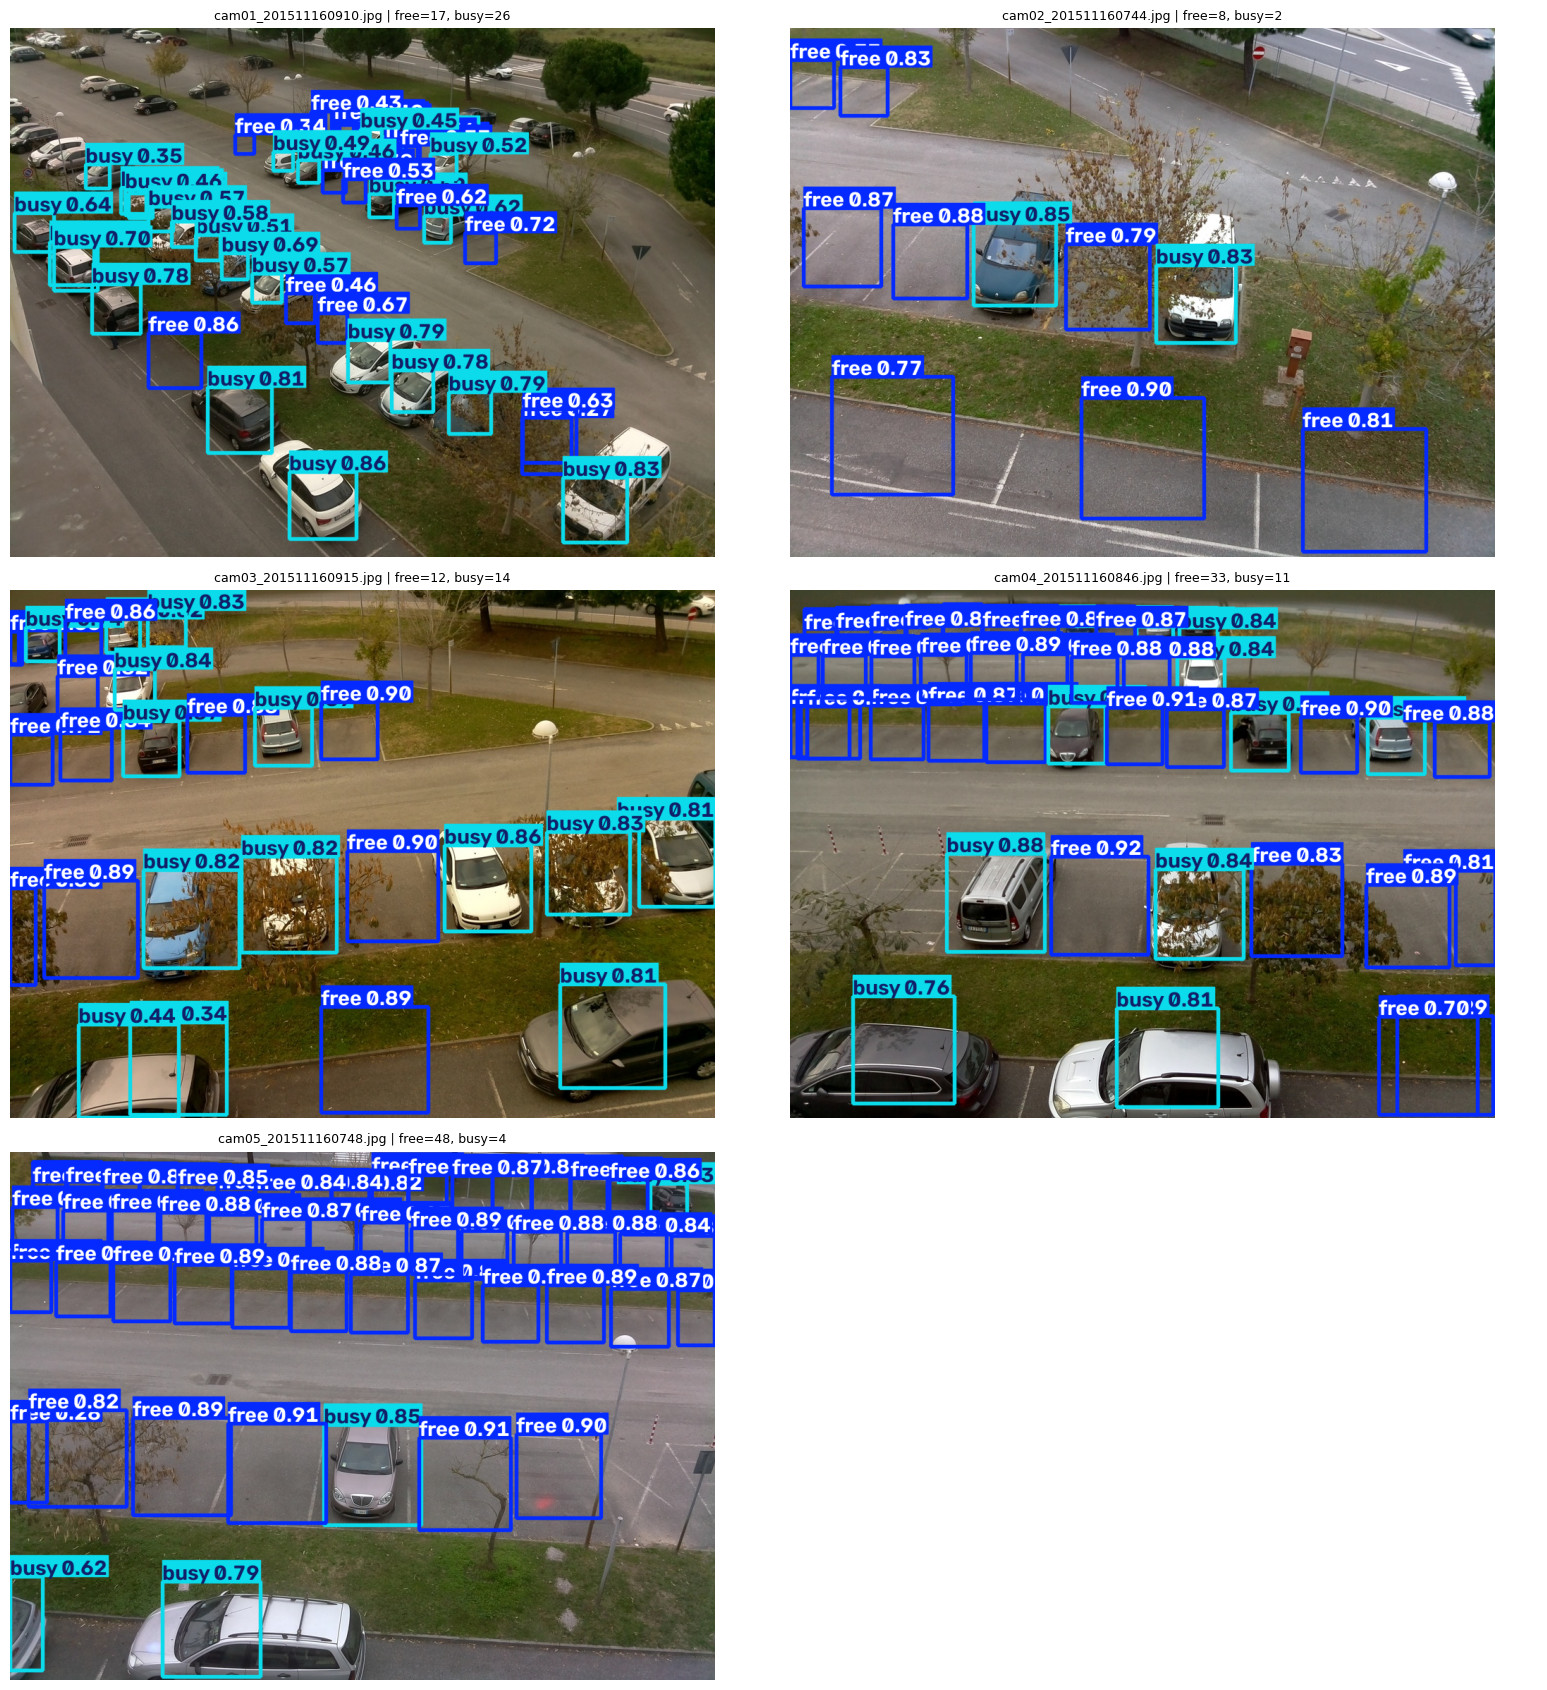

,image,free,busy,total
0,cam01_201511160910.jpg,17,26,43
1,cam02_201511160744.jpg,8,2,10
2,cam03_201511160915.jpg,12,14,26
3,cam04_201511160846.jpg,33,11,44
4,cam05_201511160748.jpg,48,4,52


In [13]:
test_paths=sorted(DATA/"images"/"test"/r["file"] for r in manifest if r["split"]=="test")
# Five cameras: a more varied demonstration than five consecutive frames.
demo=[];seen_cameras=set()
for path in test_paths:
    camera=path.stem.split("_")[0]
    if camera not in seen_cameras:demo.append(path);seen_cameras.add(camera)
    if len(demo)==5:break
fig,axes=plt.subplots(3,2,figsize=(16,17));demo_counts=[]
for ax,path in zip(axes.flat,demo):
    result=selected_model.predict(str(path),imgsz=int(chosen["imgsz"]),conf=.25,iou=.7,device=DEVICE,save=False,verbose=False)[0]
    cls=result.boxes.cls.cpu().numpy().astype(int)
    counts={"image":path.name,"free":int((cls==0).sum()),"busy":int((cls==1).sum()),"total":len(cls)};demo_counts.append(counts)
    ax.imshow(result.plot()[:,:,::-1]);ax.axis("off");ax.set_title(f"{path.name} | free={counts['free']}, busy={counts['busy']}",fontsize=9)
axes.flat[-1].axis("off");plt.tight_layout();plt.show();display(pd.DataFrame(demo_counts))

## 7. Ошибки: три отдельных случая
Проверяем все тестовые кадры при confidence 0.25 и IoU совпадения 0.50. Сопоставление выполняется по геометрии, после чего отдельно считаются неверные классы. Это диагностический аудит, а не повторный расчёт стандартного mAP.

Для трёх кадров с наибольшим количеством ошибок показываем ground truth рядом с предсказанием. При интерпретации различаем пропуски, лишние рамки, неверный класс и неточную локализацию. Возможные причины — малый размер мест, перекрытия, неоднозначная разметка, тени; причину нужно проверять по конкретному изображению.

Full test audit at conf=.25, matching IoU=.50: {'missed': 187, 'extra': 2052, 'wrong_class': 47}


,image,missed,extra,wrong_class
0,cam09_201511211717.jpg,17,13,2
1,cam09_201511211747.jpg,21,7,2
2,cam01_201601121217.jpg,7,15,1
3,cam01_201601120917.jpg,7,14,1
4,cam01_201511211340.jpg,5,14,1
5,cam01_201511211310.jpg,5,13,1
6,cam01_201601160735.jpg,10,10,0
7,cam01_201511160910.jpg,4,12,1
8,cam01_201511211210.jpg,4,10,1
9,cam01_201511211410.jpg,4,10,1


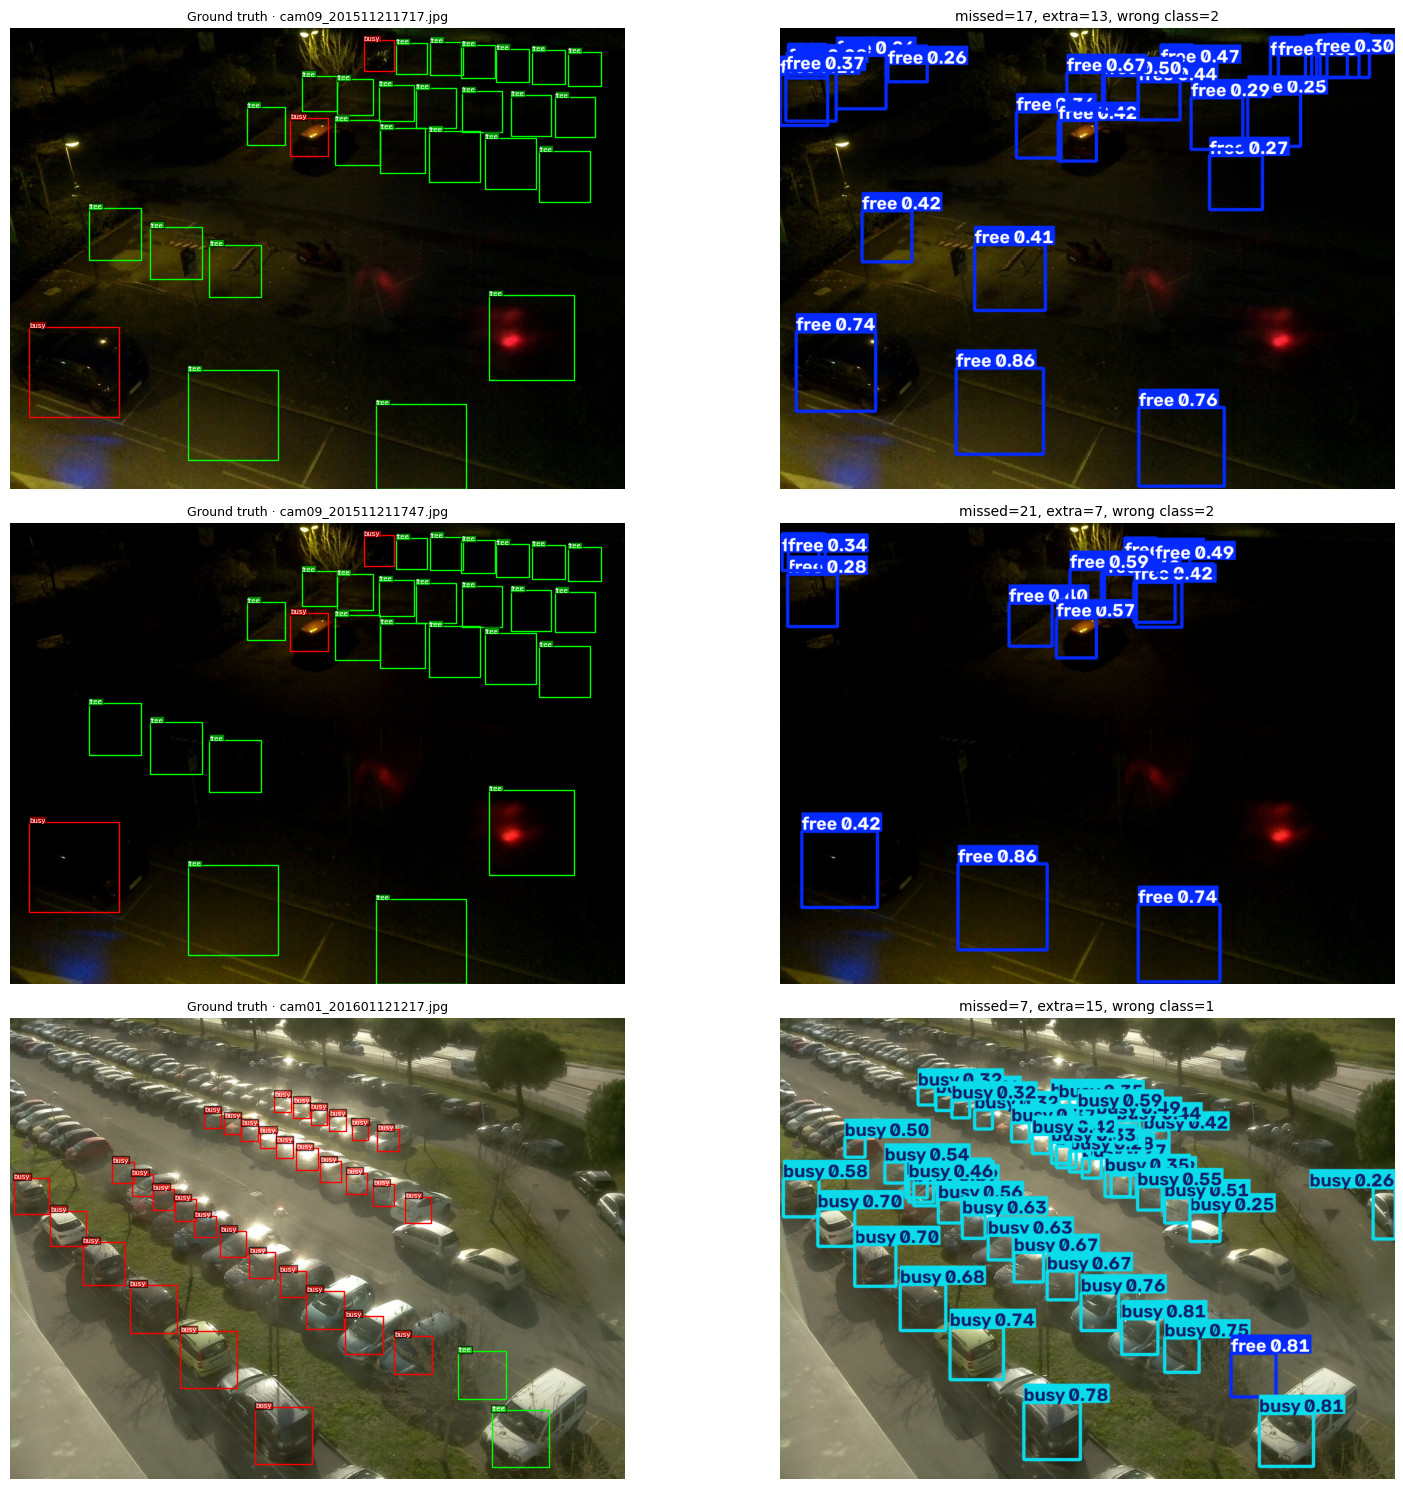

In [14]:
def box_iou(a,b):
    x1,y1=max(a[0],b[0]),max(a[1],b[1]);x2,y2=min(a[2],b[2]),min(a[3],b[3])
    inter=max(0,x2-x1)*max(0,y2-y1)
    aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]);bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/max(aa+bb-inter,1e-9)
errors=[];totals=Counter()
for path in test_paths:
    # Process one image at a time: do not warm up with all test images as a single batch.
    result=selected_model.predict(str(path),imgsz=int(chosen["imgsz"]),conf=.25,iou=.7,device=DEVICE,save=False,verbose=False)[0]
    h,w=result.orig_shape;truth=[]
    for line in (DATA/"labels"/"test"/(path.stem+".txt")).read_text().splitlines():
        c,cx,cy,bw,bh=map(float,line.split());truth.append((int(c),[(cx-bw/2)*w,(cy-bh/2)*h,(cx+bw/2)*w,(cy+bh/2)*h]))
    predictions=[(int(c),b.tolist()) for c,b in zip(result.boxes.cls.cpu().numpy(),result.boxes.xyxy.cpu().numpy())]
    pairs=sorted(((box_iou(gt[1],pr[1]),gi,pi) for gi,gt in enumerate(truth) for pi,pr in enumerate(predictions)),reverse=True)
    used_gt=set();used_pr=set();wrong=0
    for overlap,gi,pi in pairs:
        if overlap<.5:break
        if gi not in used_gt and pi not in used_pr:
            used_gt.add(gi);used_pr.add(pi);wrong+=truth[gi][0]!=predictions[pi][0]
    row={"image":path.name,"missed":len(truth)-len(used_gt),"extra":len(predictions)-len(used_pr),"wrong_class":int(wrong)}
    totals.update({k:row[k] for k in ("missed","extra","wrong_class")})
    if any(row[k] for k in ("missed","extra","wrong_class")):errors.append(row)
errors.sort(key=lambda r:r["missed"]+r["extra"]+2*r["wrong_class"],reverse=True)
print("Full test audit at conf=.25, matching IoU=.50:",dict(totals));display(pd.DataFrame(errors[:10]))
if len(errors)<3:print("Fewer than three failing frames; show the most challenging available examples.")
fig,axes=plt.subplots(min(3,max(1,len(errors))),2,figsize=(17,5*min(3,max(1,len(errors)))));axes=np.asarray(axes).reshape(-1,2)
for (left,right),row in zip(axes,errors[:3]):
    path=DATA/"images"/"test"/row["image"]
    draw_ground_truth(left,path,DATA/"labels"/"test"/(path.stem+".txt"));left.set_title("Ground truth · "+path.name,fontsize=9)
    result=selected_model.predict(str(path),imgsz=int(chosen["imgsz"]),conf=.25,iou=.7,device=DEVICE,save=False,verbose=False)[0]
    right.imshow(result.plot()[:,:,::-1]);right.axis("off");right.set_title(f"missed={row['missed']}, extra={row['extra']}, wrong class={row['wrong_class']}",fontsize=10)
plt.tight_layout();plt.show()

## Анализ трёх реальных ошибок

**1. cam09_201511211717.jpg — Occupied spaces called free**

In low light, occupied spaces are labeled free; extra boxes also appear near trees. Add labeled night examples and evaluate false free-space reports separately.

**2. cam09_201511211747.jpg — Missed spaces at night**

Very dark regions contain many labeled spaces that the detector misses or misaligns. Improve camera exposure and evaluate a separate night subset.

**3. cam01_201601121217.jpg — ROI boundaries and label ambiguity**

Some extra boxes lie outside labeled slots. A free-labeled box overlaps the foreground van. Review slot boundaries and ambiguous labels before validating ROI filtering.

Это гипотезы по визуальному анализу, а не доказанные причины. Аудит при confidence 0.25 имеет 187 пропусков, 2 052 лишние рамки и 47 неверных классов на 347 кадрах. Эти числа относятся к другому порогу и диагностическому сопоставлению, чем стандартные P/R. Высокий mAP не гарантирует надёжный подсчёт свободных мест при низком пороге.

## 8. Интерпретация и ограничения
- Сравниваем baseline и три изменения на одной фиксированной выборке и одном seed. Вывод относится к этому бюджету в 10 эпох, а не к полностью сошедшимся моделям или всем парковкам.
- Фото разных дат разнесены, но камеры и парковка общие. Результат на парковке университета не проверялся.
- 57 213 рамок — повторные наблюдения мест на 1 600 кадрах, не число уникальных физических мест.
- Для применения нужны местные фотографии и разметка, проверка нового ракурса, выбор порога на validation и оценка ошибок подсчёта.
- Конкретный практический шаг: настроить confidence на validation под допустимое число ложных свободных мест и проверить его на локальной тестовой выборке.

Для защиты объясните: как соединены CSV, зачем разделять даты, почему AdamW задан явно, чем LR отличается от image size, как выбрана модель, что означает mAP и почему это не campus-ready система.

In [15]:
# Preserve evidence/checkpoints without separate plot folders; all figures remain inline.
if RUN_TRAINING:
    metadata={"selected":{k:v for k,v in chosen.items() if k not in ("history","configuration")},"test":test_metrics,"evaluation":{"candidate_conf":.001,"nms_iou":.7,"demo_conf":.25,"matching_iou":.5},"splits":split_summary.to_dict(orient="records"),"audit":dict(totals),"failure_cases":errors[:3]}
    metadata["selected"]["weights"] = FINAL_WEIGHTS.name
    (PROJECT/"model_metadata.json").write_text(json.dumps(metadata,indent=2))
    with zipfile.ZipFile(PROJECT/"experiment_checkpoints.zip","w",compression=zipfile.ZIP_DEFLATED) as z:
        for run in runs:
            path=RUN_DIR/run["name"]
            for relative in ("weights/best.pt","results.csv","args.yaml","completed.json"):
                z.write(path/relative,arcname=run["name"]+"/"+relative)
    print("Kept selected weights, machine-readable metadata and four best checkpoints with epoch logs in one ZIP.")
# Only remove logs after metrics, plots and checkpoint archive have been produced.
if RUN_DIR.exists():shutil.rmtree(RUN_DIR)
print("Visualizations are embedded in this notebook. Training temporary folders removed.")
# Release the project lock only after outputs and checkpoints are safely stored.
fcntl.flock(TRAINING_LOCK, fcntl.LOCK_UN)
TRAINING_LOCK.close()

DATA = PROJECT / "data" / "parking_yolo"
DATA_YAML = DATA / "dataset.yaml"
test_paths = sorted(DATA/"images"/"test"/r["file"] for r in manifest if r["split"]=="test")


Kept selected weights, machine-readable metadata and four best checkpoints with epoch logs in one ZIP.


Visualizations are embedded in this notebook. Training temporary folders removed.
